In [31]:
# === Configuración para Google Colab (iPad / navegador). En una compu con todo instalado, esta celda no hace nada. ===
# USAR_DRIVE = False → trabaja en el espacio temporal de Colab (no usa tu Drive). Al final se descargan las salidas en un .zip.
# USAR_DRIVE = True  → guarda todo en MyDrive/TP_geodatos (necesita ~100 MB libres en Drive).
USAR_DRIVE = False

import os, subprocess, sys
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio", "osmnx", "folium", "plotly",
                    "statsmodels", "earthengine-api", "contextily"], check=True)
    if USAR_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        CARPETA = "/content/drive/MyDrive/TP_geodatos/geo_tp_utn"
    else:
        CARPETA = "/content/geo_tp_utn"
    if not os.path.exists(CARPETA):
        os.makedirs(os.path.dirname(CARPETA), exist_ok=True)
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/Kiandro1/geo_tp_utn.git", CARPETA], check=True)
    os.chdir(CARPETA)
print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /content/geo_tp_utn


# Barrios cerrados, humedales y riesgo en el partido de Berazategui (1989–2024)
**Diplomatura en Ciencia de Datos y Análisis Avanzado (UTN) · Módulo 4: Visualización de datos*
**Integrantes:**

**Pregunta.** ¿Qué tipo de suelo reemplazan los barrios cerrados frente al crecimiento urbano tradicional, cuánta urbanización queda expuesta sobre ex-humedales y qué puede pasar hacia 2034?

**Estructura:** Parte A: datos y validación · Parte B: mapas de usos del suelo · Parte C: análisis con intervalos · Conclusiones · Limitaciones · Fuentes.

# Parte A · Datos y validación

In [32]:
# Requiere: pip install -r requirements.txt
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import pyogrio
import rasterio
from pyproj import CRS
from rasterio.features import geometry_mask, rasterize
from rasterio.mask import mask as rio_mask
from rasterio.transform import from_origin
from rasterio.warp import Resampling, reproject

RAIZ = Path(".")
DATOS = RAIZ / "data"
SALIDAS = RAIZ / "salidas"
(DATOS / "mapbiomas").mkdir(parents=True, exist_ok=True)
SALIDAS.mkdir(exist_ok=True)

# POSGAR 2007 / Argentina 6 (faja 6, meridiano central -57°), la faja que corresponde a Berazategui (~58,2° O).
# La base anterior usaba EPSG:5343 (faja 1, meridiano -72°, pensada para la cordillera).
CRS_TRABAJO = "EPSG:5348"
RES = 30                                  # metros: resolución nativa de MapBiomas (Landsat)
HA_PIXEL = RES * RES / 10_000             # 0,09 ha por píxel
ANIOS = [1989, 1994, 1999, 2004, 2009, 2014, 2019, 2024]   # cortes quinquenales con pasos iguales


def exigir(condicion, mensaje):
    # Freno explícito: un chequeo de calidad fallido detiene el notebook con un mensaje claro.
    if not condicion:
        raise ValueError("CHEQUEO DE CALIDAD FALLIDO → " + mensaje)


exigir("Argentina 6" in CRS(CRS_TRABAJO).name, f"{CRS_TRABAJO} no es la faja 6: {CRS(CRS_TRABAJO).name}")
print("CRS de trabajo:", CRS(CRS_TRABAJO).name)

CRS de trabajo: POSGAR 2007 / Argentina 6


## 1. Auditoría de la base anterior

Es lo mismo que haría un actuario con una cartera heredada antes de tarifar: revisar qué contiene realmente la base. Se chequean cuatro cosas:

1. **Exposición (denominador):** ¿el límite es el partido completo?
2. **Registros duplicados o mal clasificados:** ¿cuántos elementos hay y cuáles se repiten?
3. **Variables simuladas:** ¿los años son datos observados o generados?
4. **Georreferenciación:** ¿las capas caen donde deberían?

In [33]:
hallazgos = []


def registrar(tema, resultado, impacto):
    hallazgos.append({"Tema": tema, "Resultado": resultado, "Impacto": impacto})


def centro_lonlat(gdf):
    minx, miny, maxx, maxy = gdf.to_crs(4326).total_bounds
    return (minx + maxx) / 2, (miny + maxy) / 2


def en_berazategui(lon, lat):
    return -58.5 < lon < -57.9 and -35.0 < lat < -34.7


# 1.1 Límite anterior: CRS y superficie
ruta_lim_viejo = RAIZ / "berazategui_limite.gpkg"
if ruta_lim_viejo.exists():
    lim_viejo = gpd.read_file(ruta_lim_viejo)
    registrar("CRS de las capas", CRS(lim_viejo.crs).name,
              "OK" if "Argentina 6" in CRS(lim_viejo.crs).name else "Faja incorrecta para Berazategui")
    sup = lim_viejo.to_crs(CRS_TRABAJO).area.sum() / 1e4
    registrar("Superficie del límite", f"{sup:,.0f} ha",
              "OK" if sup > 15_000 else "Demasiado chico para el partido (~18.800 ha): es la localidad, deja Hudson afuera")

# 1.2 Capas del gpkg de barrios
ruta_b_viejo = RAIZ / "barrios_cerrados_berazategui_procesado.gpkg"
if ruta_b_viejo.exists():
    capas = [c[0] for c in pyogrio.list_layers(ruta_b_viejo)]
    registrar("Capas en el gpkg de barrios", ", ".join(capas),
              f"gpd.read_file sin layer= lee la primera: '{capas[0]}'")
    for capa in capas:
        g = gpd.read_file(ruta_b_viejo, layer=capa)
        dup = int(g.geometry.normalize().to_wkb().duplicated().sum())
        nombres = g["nombre"] if "nombre" in g else g.get("name", pd.Series(dtype=str))
        lon, lat = centro_lonlat(g)
        registrar(f"Capa '{capa}'",
                  f"{len(g)} elementos; {dup} geometrías duplicadas; columna anio: {'anio' in g.columns}",
                  "; ".join(filter(None, [
                      "Duplicados = riesgo contado dos veces" if dup else "",
                      "Sin años: el código anterior los generaba con np.random" if "anio" not in g.columns else "Años sin fuente citada",
                      "Incluye complejos habitacionales" if nombres.astype(str).str.contains("Complejo Habitacional").any() else "",
                  ])))
        registrar(f"Ubicación capa '{capa}'", f"centro lon {lon:.2f}, lat {lat:.2f}",
                  "OK" if en_berazategui(lon, lat) else "FUERA de Berazategui (coordenadas mal cargadas)")

# 1.3 Capas que el notebook anterior esperaba
for f in ["bosques_arboledas.gpkg", "pulmones_verdes_parques.gpkg", "campos_sin_urbanizar.gpkg"]:
    if not (RAIZ / f).exists():
        registrar(f"Archivo {f}", "No existe", "El código anterior lo reemplazaba por una capa vacía sin avisar")

# 1.4 Años simulados en el notebook anterior
ruta_nb_viejo = RAIZ / "geo_bera_utn.ipynb"
if ruta_nb_viejo.exists():
    texto = ruta_nb_viejo.read_text(encoding="utf-8")
    registrar("Generación aleatoria de años", f"'np.random' aparece {texto.count('np.random')} veces",
              "La evolución temporal dependía de la semilla, no de datos" if "np.random" in texto else "OK")

auditoria = pd.DataFrame(hallazgos)
auditoria.to_csv(SALIDAS / "auditoria_base_anterior.csv", index=False)
pd.set_option("display.max_colwidth", 120)
auditoria

,Tema,Resultado,Impacto
0,CRS de las capas,POSGAR 2007 / Argentina 1,Faja incorrecta para Berazategui
1,Superficie del límite,"3,131 ha","Demasiado chico para el partido (~18.800 ha): es la localidad, deja Hudson afuera"
2,Capas en el gpkg de barrios,"barrios_identificados, barrios_cerrados_berazategui_procesado",gpd.read_file sin layer= lee la primera: 'barrios_identificados'
3,Capa 'barrios_identificados',5 elementos; 1 geometrías duplicadas; columna anio: False,Duplicados = riesgo contado dos veces; Sin años: el código anterior los generaba con np.random; Incluye complejos ha...
4,Ubicación capa 'barrios_identificados',"centro lon -58.22, lat -34.76",OK
5,Capa 'barrios_cerrados_berazategui_procesado',11 elementos; 0 geometrías duplicadas; columna anio: True,Años sin fuente citada
6,Ubicación capa 'barrios_cerrados_berazategui_procesado',"centro lon -33.68, lat -28.50",FUERA de Berazategui (coordenadas mal cargadas)
7,Archivo bosques_arboledas.gpkg,No existe,El código anterior lo reemplazaba por una capa vacía sin avisar
8,Archivo pulmones_verdes_parques.gpkg,No existe,El código anterior lo reemplazaba por una capa vacía sin avisar
9,Archivo campos_sin_urbanizar.gpkg,No existe,El código anterior lo reemplazaba por una capa vacía sin avisar


**Lectura.** La base anterior no sirve para sacar conclusiones: el denominador es equivocado, hay elementos duplicados y mal clasificados, los años son simulados y faltan capas que se reemplazaban en silencio por capas vacías. Por eso se reconstruye con fuentes oficiales y con chequeos que frenan la ejecución.

## 2. Límite del partido

Si existe `data/limite_partido_ign.gpkg` (departamento *Berazategui*, descargado del IGN), se usa ese archivo. Si no, se descarga el polígono del **partido** desde OpenStreetMap. El chequeo de superficie evita repetir el error de usar la localidad.

In [34]:
ruta_ign = DATOS / "limite_partido_ign.gpkg"
if ruta_ign.exists():
    limite = gpd.read_file(ruta_ign)
    col = next((c for c in limite.columns if c.lower() in ("nam", "nombre", "name", "departamento")), None)
    if col is not None and len(limite) > 1:
        limite = limite[limite[col].astype(str).str.contains("Berazategui", case=False)]
    fuente_limite = "IGN"
else:
    import osmnx as ox
    limite = ox.geocode_to_gdf("Partido de Berazategui, Buenos Aires, Argentina")
    fuente_limite = "OpenStreetMap (Nominatim)"

limite = limite.to_crs(CRS_TRABAJO)[["geometry"]].dissolve().reset_index(drop=True)
SUP_PARTIDO_HA = limite.area.iloc[0] / 1e4
print(f"Fuente: {fuente_limite} | Superficie: {SUP_PARTIDO_HA:,.0f} ha")
exigir(15_000 < SUP_PARTIDO_HA < 23_000,
       f"el límite mide {SUP_PARTIDO_HA:,.0f} ha y el partido tiene ~18.800 ha. ¿Se descargó la localidad?")
limite.to_file(SALIDAS / "limite_partido.gpkg", driver="GPKG")

Fuente: OpenStreetMap (Nominatim) | Superficie: 21,818 ha


## 3. Cobertura del suelo: MapBiomas Argentina (Colección 2)

**Cómo se obtienen los rásteres** (el código prueba estas opciones en orden y guarda una copia local de cada año):
1. **Archivo local** `data/mapbiomas/mapbiomas_<año>.tif`, exportado desde [plataforma.argentina.mapbiomas.org](https://plataforma.argentina.mapbiomas.org) (*Crear análisis* → recorte Berazategui).
2. **Google Earth Engine** (recomendado en Colab o iPad): lee el recorte del partido desde el asset público de MapBiomas, sin descargar el mapa nacional. Requiere una cuenta gratuita de Earth Engine y un proyecto de Google Cloud, que se completa en `GEE_PROYECTO`.
3. **Archivo nacional publicado**: se lee solo la ventana del partido. La descarga directa puede estar suspendida.

Si ninguna opción funciona, el notebook se detiene e indica qué año falta.

**Leyenda.** Los códigos se agrupan en las categorías del análisis. Hay que verificarlos contra *Códigos de la leyenda – Colección 2* (`Leyenda_Code.pdf`), en argentina.mapbiomas.org. Si aparece un código no mapeado, el notebook lo avisa.

In [35]:
GRUPOS = ["Humedal", "Bosque", "Pastizal", "Agropecuario", "Agua", "Urbano tradicional", "Barrio cerrado", "Otro"]
IDX = {g: i for i, g in enumerate(GRUPOS)}
CODIGOS_URBANOS = (24,)                   # 24 = Áreas urbanas

CODIGO_A_GRUPO = {
    3: "Bosque", 4: "Bosque",             # bosques cerrados / abiertos
    6: "Humedal", 11: "Humedal",          # bosque inundable / herbáceas inundables (humedal)
    12: "Pastizal",                       # herbáceas (pastizal)
    9: "Agropecuario", 15: "Agropecuario", 18: "Agropecuario", 19: "Agropecuario",
    20: "Agropecuario", 21: "Agropecuario", 36: "Agropecuario", 39: "Agropecuario",
    40: "Agropecuario", 41: "Agropecuario",
    24: "Urbano tradicional",             # áreas urbanas (los barrios cerrados se separan en 02)
    33: "Agua", 26: "Agua",
    22: "Otro", 23: "Otro", 25: "Otro", 27: "Otro", 30: "Otro",
}

URL_NACIONAL = ("https://storage.googleapis.com/mapbiomas-public/initiatives/argentina/"
                "collection-2/coverage/argentina_coverage_{anio}.tif")

# Grilla común: faja 6, 30 m, cubriendo el partido. Todos los años se llevan a esta grilla.
xmin, ymin, xmax, ymax = limite.total_bounds
xmin, ymax = np.floor(xmin / RES) * RES, np.ceil(ymax / RES) * RES
ANCHO, ALTO = int(np.ceil((xmax - xmin) / RES)), int(np.ceil((ymax - ymin) / RES))
TRANSFORM = from_origin(xmin, ymax, RES, RES)
DENTRO = ~geometry_mask(limite.geometry, out_shape=(ALTO, ANCHO), transform=TRANSFORM)
print(f"Grilla {ALTO} × {ANCHO} píxeles; {DENTRO.sum() * HA_PIXEL:,.0f} ha dentro del partido")


GEE_PROYECTO = "project-ef492ad3-2c57-4d52-a7a"
GEE_ASSET = "projects/mapbiomas-public/assets/argentina/lulc/collection2/mapbiomas_argentina_collection2_integration_v3"
_gee = {"listo": False}  # Corregido: iniciar en False para forzar la inicialización

def descargar_gee(anio, destino):
    import ee, requests
    if not _gee["listo"]:
        exigir(GEE_PROYECTO != "", "Debe especificar un proyecto de GEE válido.")
        try:
            import google.auth
            credenciales, _ = google.auth.default(scopes=[
                "https://www.googleapis.com/auth/earthengine",
                "https://www.googleapis.com/auth/cloud-platform"])
            ee.Initialize(credenciales, project=GEE_PROYECTO)
        except Exception:
            try:
                ee.Initialize(project=GEE_PROYECTO)
            except Exception:
                ee.Authenticate()
                ee.Initialize(project=GEE_PROYECTO)
        _gee["listo"] = True
    img = ee.Image(GEE_ASSET)
    banda = f"classification_{anio}"
    bandas = img.bandNames().getInfo()
    exigir(banda in bandas, f"el asset no tiene la banda {banda}. Bandas disponibles: {bandas[:5]}…")
    region = ee.Geometry(limite.to_crs(4326).buffer(0).geometry.iloc[0].__geo_interface__)
    url = img.select(banda).getDownloadURL({"region": region, "scale": RES, "crs": "EPSG:4326", "format": "GEO_TIFF"})
    r = requests.get(url, timeout=300)
    r.raise_for_status()
    destino.write_bytes(r.content)


def abrir_mapbiomas(anio):
    local = DATOS / "mapbiomas" / f"mapbiomas_{anio}.tif"
    if local.exists():
        return rasterio.open(local), f"local ({local.name})"
    if GEE_PROYECTO:
        descargar_gee(anio, local)
        return rasterio.open(local), "Google Earth Engine (copia local guardada)"
    try:
        return rasterio.open("/vsicurl/" + URL_NACIONAL.format(anio=anio)), "remoto (ventana del partido)"
    except rasterio.errors.RasterioIOError as e:
        raise FileNotFoundError(
            f"Falta MapBiomas {anio}. Opciones: completar GEE_PROYECTO (Earth Engine) o exportarlo "
            f"recortado a Berazategui desde la plataforma y guardarlo como {local}") from e


def cargar_anio(anio):
    src, origen = abrir_mapbiomas(anio)
    with src:
        geom_src = limite.to_crs(src.crs).geometry
        recorte, tr = rio_mask(src, geom_src, crop=True, all_touched=True, nodata=0, filled=True)
        destino = np.zeros((ALTO, ANCHO), dtype=np.uint8)
        reproject(recorte[0], destino, src_transform=tr, src_crs=src.crs,
                  dst_transform=TRANSFORM, dst_crs=CRS_TRABAJO,
                  resampling=Resampling.nearest, src_nodata=0, dst_nodata=0)
    return destino, origen


capas, origen_mapbiomas = [], {}
for anio in ANIOS:
    arr, origen_mapbiomas[anio] = cargar_anio(anio)
    capas.append(arr)
    print(anio, "→", origen_mapbiomas[anio])

CODIGOS = np.stack(capas)
CODIGOS[:, ~DENTRO] = 0

cobertura = (CODIGOS[:, DENTRO] > 0).mean(axis=1)
for anio, c in zip(ANIOS, cobertura):
    exigir(c > 0.95, f"MapBiomas {anio} cubre solo {c:.1%} del partido")

presentes = set(np.unique(CODIGOS[:, DENTRO]).tolist()) - {0}
sin_mapear = sorted(presentes - set(CODIGO_A_GRUPO))
if sin_mapear:
    warnings.warn(f"Códigos sin mapear (quedan como 'Otro'): {sin_mapear}. Revisar Leyenda_Code.pdf")

# Superficie por código y año, para inspeccionar la leyenda
sup_codigo = pd.DataFrame({a: pd.Series(np.bincount(CODIGOS[i][DENTRO], minlength=256)) * HA_PIXEL
                           for i, a in enumerate(ANIOS)})
sup_codigo = sup_codigo[sup_codigo.sum(axis=1) > 0].drop(index=0, errors="ignore")
sup_codigo.insert(0, "Grupo", [CODIGO_A_GRUPO.get(c, "Otro (sin mapear)") for c in sup_codigo.index])
sup_codigo.round(0)

Grilla 800 × 750 píxeles; 21,818 ha dentro del partido
1989 → local (mapbiomas_1989.tif)
1994 → local (mapbiomas_1994.tif)
1999 → local (mapbiomas_1999.tif)
2004 → local (mapbiomas_2004.tif)
2009 → local (mapbiomas_2009.tif)
2014 → local (mapbiomas_2014.tif)
2019 → local (mapbiomas_2019.tif)
2024 → local (mapbiomas_2024.tif)


/tmp/ipykernel_745/3759945780.py:104: UserWarning: Códigos sin mapear (quedan como 'Otro'): [66, 77]. Revisar Leyenda_Code.pdf
  warnings.warn(f"Códigos sin mapear (quedan como 'Otro'): {sin_mapear}. Revisar Leyenda_Code.pdf")


,Grupo,1989,1994,1999,2004,2009,2014,2019,2024
3,Bosque,1026.0,885.0,1401.0,1333.0,1136.0,1398.0,1463.0,533.0
4,Bosque,11.0,8.0,4.0,43.0,208.0,260.0,238.0,205.0
6,Humedal,2182.0,2628.0,2317.0,2726.0,3223.0,2950.0,2868.0,3692.0
9,Agropecuario,299.0,279.0,755.0,372.0,297.0,562.0,736.0,651.0
11,Humedal,203.0,51.0,97.0,80.0,61.0,68.0,78.0,118.0
12,Pastizal,7048.0,6666.0,5824.0,6045.0,4950.0,4517.0,5133.0,5892.0
15,Agropecuario,3403.0,3734.0,3513.0,2816.0,3057.0,2510.0,1381.0,1250.0
19,Agropecuario,1150.0,830.0,858.0,923.0,974.0,1277.0,1296.0,742.0
24,Urbano tradicional,6407.0,6638.0,6975.0,7394.0,7839.0,8181.0,8470.0,8586.0
25,Otro,26.0,22.0,30.0,12.0,11.0,29.0,32.0,40.0


In [36]:
from google.colab import auth


import google.auth, ee
credenciales, _ = google.auth.default(scopes=[
    "https://www.googleapis.com/auth/earthengine",
    "https://www.googleapis.com/auth/cloud-platform"])
ee.Initialize(credenciales, project="project-ef492ad3-2c57-4d52-a7a")
print("Earth Engine OK")


Earth Engine OK


## 4. Barrios cerrados

**Fuente preferida:** el Registro Provincial de Urbanizaciones Cerradas, exportado desde URBASIG como `data/urbanizaciones_cerradas_urbasig.gpkg`.

**Alternativa:** OpenStreetMap (`landuse=residential`), clasificando como cerrado lo etiquetado como privado o cerrado, o con nombre de country, club de campo o barrio privado. Se **excluyen** de forma explícita los complejos habitacionales, que la base anterior contaba como barrios cerrados. La tabla resultante se imprime para revisarla a mano.

In [37]:
ruta_urbasig = DATOS / "urbanizaciones_cerradas_urbasig.gpkg"
if ruta_urbasig.exists():
    barrios = gpd.read_file(ruta_urbasig).to_crs(CRS_TRABAJO)
    col = next((c for c in barrios.columns if c.lower() in ("nombre", "name", "denominacion", "denominación")), None)
    barrios["nombre"] = barrios[col].astype(str) if col else "s/n"
    fuente_barrios = "Registro Provincial de Urbanizaciones Cerradas (URBASIG)"
else:
    import osmnx as ox
    osm = ox.features_from_polygon(limite.to_crs(4326).geometry.iloc[0], tags={"landuse": "residential"})
    osm = osm[osm.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(CRS_TRABAJO)

    def campo(c):
        return osm[c].astype(str).str.lower() if c in osm.columns else pd.Series("", index=osm.index)

    nombre = campo("name").replace("nan", "")
    patron = r"country|club de campo|barrio (?:privado|cerrado)|chacras|fincas|pueblos? del plata|haras|lagoon|greenville|abril"
    es_cerrado = (campo("residential").isin(["gated", "private"]) | campo("gated").eq("yes")
                  | campo("access").eq("private") | nombre.str.contains(patron, regex=True))
    excluido = nombre.str.contains(r"complejo habitacional|plan federal|procrear|monoblock", regex=True)
    barrios = osm.loc[es_cerrado & ~excluido, ["geometry"]].copy()
    barrios["nombre"] = osm.loc[barrios.index, "name"].fillna("s/n") if "name" in osm else "s/n"
    fuente_barrios = "OpenStreetMap (clasificación por etiquetas y nombre)"

barrios = gpd.clip(barrios[["nombre", "geometry"]].reset_index(drop=True), limite)
n_inicial = len(barrios)
barrios = barrios[~barrios.geometry.normalize().to_wkb().duplicated()]
barrios["sup_ha"] = barrios.area / 1e4
barrios = barrios[barrios["sup_ha"] >= 1].reset_index(drop=True)
print(f"Fuente: {fuente_barrios}")
print(f"{n_inicial} polígonos → {len(barrios)} tras quitar duplicados y polígonos < 1 ha")
exigir(len(barrios) > 0, "no quedó ningún barrio cerrado: revisar la fuente")
barrios.drop(columns="geometry").sort_values("sup_ha", ascending=False)

Fuente: OpenStreetMap (clasificación por etiquetas y nombre)
20 polígonos → 20 tras quitar duplicados y polígonos < 1 ha


,nombre,sup_ha
19,Puerto Trinidad,351.856712
11,Club de Campo Abril,308.744493
14,s/n,129.769519
18,Hudson Lagoon,114.183141
10,s/n,101.486585
2,El Carmen,83.461014
4,s/n,66.535401
3,s/n,59.199650
1,s/n,45.084560
17,Las Golondrinas,35.946764


### 4.1 Año de urbanización observado (no cargado a mano)

Para cada barrio se toma el **primer año de corte en que al menos el 25 % de su huella aparece como área urbana** en MapBiomas. Es un dato observado por satélite, reproducible y sin supuestos manuales. En el notebook 02 se mide la sensibilidad al umbral (15 %, 25 % y 40 %).

Si se cuenta con años de lanzamiento documentados, se pueden cargar en `data/barrios_anio_manual.csv` (columnas `nombre, anio, fuente`) y tienen prioridad.

In [38]:
ID_BARRIO = rasterize(((geom, i + 1) for i, geom in enumerate(barrios.geometry)),
                      out_shape=(ALTO, ANCHO), transform=TRANSFORM, fill=0, dtype="int32")
ID_BARRIO[~DENTRO] = 0


def anio_urbanizacion(codigos, id_barrio, n_barrios, anios, codigos_urbanos=(24,), umbral=0.25):
    # Primer año de corte en que la fracción urbana de la huella del barrio supera el umbral.
    ids = id_barrio.ravel()
    sel = ids > 0
    total = np.bincount(ids[sel], minlength=n_barrios + 1).astype(float)
    fracs = np.vstack([
        np.bincount(ids[sel], weights=np.isin(codigos[t], codigos_urbanos).ravel()[sel], minlength=n_barrios + 1)
        / np.maximum(total, 1)
        for t in range(len(anios))
    ])[:, 1:]                                  # (años, barrios)
    anio = np.full(n_barrios, np.nan)
    for b in range(n_barrios):
        supera = np.flatnonzero(fracs[:, b] >= umbral)
        if supera.size:
            anio[b] = anios[supera[0]]
    return anio, fracs


barrios["anio_urb"], fracs_urbanas = anio_urbanizacion(CODIGOS, ID_BARRIO, len(barrios), ANIOS, CODIGOS_URBANOS)
barrios["fuente_anio"] = "MapBiomas (≥25 % urbano)"
barrios["previo_a_1989"] = barrios["anio_urb"].eq(ANIOS[0])   # ya urbanizado en el primer corte: suelo previo desconocido

ruta_manual = DATOS / "barrios_anio_manual.csv"
if ruta_manual.exists():
    manual = pd.read_csv(ruta_manual)
    exigir({"nombre", "anio", "fuente"} <= set(manual.columns), "barrios_anio_manual.csv debe tener nombre, anio, fuente")
    m = barrios["nombre"].map(manual.set_index("nombre")["anio"])
    barrios.loc[m.notna(), "fuente_anio"] = barrios["nombre"].map(manual.set_index("nombre")["fuente"])
    barrios["anio_urb"] = m.fillna(barrios["anio_urb"])

print(barrios["anio_urb"].value_counts(dropna=False).sort_index().rename("barrios por año de urbanización"))

anio_urb
1989.0    8
1999.0    2
2004.0    2
2009.0    2
2014.0    3
2019.0    2
2024.0    1
Name: barrios por año de urbanización, dtype: int64


## 5. Resumen de calidad y exportación

In [39]:
chequeos = pd.DataFrame([
    {"Chequeo": "CRS de trabajo", "Valor": CRS(CRS_TRABAJO).name},
    {"Chequeo": "Superficie del partido", "Valor": f"{SUP_PARTIDO_HA:,.0f} ha ({fuente_limite})"},
    {"Chequeo": "Cobertura MapBiomas mínima", "Valor": f"{cobertura.min():.1%}"},
    {"Chequeo": "Códigos sin mapear", "Valor": str(sin_mapear or "ninguno")},
    {"Chequeo": "Barrios cerrados", "Valor": f"{len(barrios)} ({fuente_barrios})"},
    {"Chequeo": "Superficie de barrios", "Valor": f"{barrios.sup_ha.sum():,.0f} ha ({barrios.sup_ha.sum() / SUP_PARTIDO_HA:.1%} del partido)"},
    {"Chequeo": "Barrios sin año detectado", "Valor": int(barrios.anio_urb.isna().sum())},
])

barrios.to_file(SALIDAS / "barrios_cerrados.gpkg", driver="GPKG")
barrios.drop(columns="geometry").to_csv(SALIDAS / "barrios_cerrados.csv", index=False)
np.savez_compressed(SALIDAS / "mapbiomas_berazategui.npz", codigos=CODIGOS, anios=np.array(ANIOS),
                    id_barrio=ID_BARRIO, dentro=DENTRO, transform=np.array(tuple(TRANSFORM))[:6])
(SALIDAS / "metadatos.json").write_text(json.dumps({
    "crs": CRS_TRABAJO, "res_m": RES, "anios": ANIOS, "grupos": GRUPOS,
    "codigo_a_grupo": {str(k): v for k, v in CODIGO_A_GRUPO.items()},
    "codigos_urbanos": list(CODIGOS_URBANOS), "fuente_limite": fuente_limite,
    "fuente_barrios": fuente_barrios, "origen_mapbiomas": {str(k): v for k, v in origen_mapbiomas.items()},
    "sup_partido_ha": SUP_PARTIDO_HA,
}, ensure_ascii=False, indent=2), encoding="utf-8")
chequeos

,Chequeo,Valor
0,CRS de trabajo,POSGAR 2007 / Argentina 6
1,Superficie del partido,"21,818 ha (OpenStreetMap (Nominatim))"
2,Cobertura MapBiomas mínima,99.9%
3,Códigos sin mapear,"[66, 77]"
4,Barrios cerrados,20 (OpenStreetMap (clasificación por etiquetas y nombre))
5,Superficie de barrios,"1,441 ha (6.6% del partido)"
6,Barrios sin año detectado,0


# Parte B · Mapas de usos del suelo
Son los mapas del notebook original de Leandro (mapa de fondo, barrios en rojo con borde blanco, etiquetas con nombre y hectáreas, límite en negro), adaptados a la base validada:
- **Límite:** el partido completo (`salidas/limite_partido.gpkg`), no la localidad.
- **Barrios:** los reales, con año de urbanización observado. Ya no se usa `np.random`.
- **Coberturas naturales:** salen de MapBiomas, en vez de capas que se cargaban vacías.
- **Proyección:** faja 6 (EPSG:5348), con escala gráfica en km y flecha de norte.

In [40]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from affine import Affine

S = Path("salidas")
meta_b = json.loads((S / "metadatos.json").read_text(encoding="utf-8"))
zb = np.load(S / "mapbiomas_berazategui.npz")
lim_b = gpd.read_file(S / "limite_partido.gpkg")
bar_b = gpd.read_file(S / "barrios_cerrados.gpkg")
anios_b = zb["anios"].tolist()
tr_b, dentro_b = Affine(*zb["transform"]), zb["dentro"]
EXTENT = (tr_b.c, tr_b.c + tr_b.a * dentro_b.shape[1], tr_b.f + tr_b.e * dentro_b.shape[0], tr_b.f)

CLASES_MAPA = ["Humedal", "Bosque", "Pastizal", "Agropecuario", "Agua", "Urbano tradicional", "Otro"]
COL_MAPA = {"Humedal": "#4a9e9a", "Bosque": "#1f6f3f", "Pastizal": "#c9b458", "Agropecuario": "#efe6c4",
            "Agua": "#2f5fb3", "Urbano tradicional": "#b5b5b5", "Otro": "#e6e6e6"}
lut_b = np.full(256, CLASES_MAPA.index("Otro"), np.uint8)
for cod, g in meta_b["codigo_a_grupo"].items():
    lut_b[int(cod)] = CLASES_MAPA.index(g) if g in CLASES_MAPA else CLASES_MAPA.index("Otro")
cmap_b = ListedColormap([COL_MAPA[c] for c in CLASES_MAPA])
LEYENDA_B = [Patch(color=COL_MAPA[c], label=c) for c in CLASES_MAPA if c != "Otro"] + \
            [Patch(facecolor="#c8102e", edgecolor="white", label="Barrio cerrado")]


def capa_suelo(t):
    m = lut_b[zb["codigos"][t]].astype(float)
    m[~dentro_b | (zb["codigos"][t] == 0)] = np.nan
    return m


def escala_y_norte(ax, km=2):
    ancho, alto = EXTENT[1] - EXTENT[0], EXTENT[3] - EXTENT[2]
    x0, y0 = EXTENT[0] + ancho * 0.05, EXTENT[2] + alto * 0.05
    ax.plot([x0, x0 + km * 1000], [y0, y0], color="k", lw=3, solid_capstyle="butt", zorder=7)
    ax.text(x0 + km * 500, y0 + alto * 0.015, f"{km} km", ha="center", fontsize=8, zorder=7)
    ax.annotate("N", xy=(0.95, 0.95), xytext=(0.95, 0.86), xycoords="axes fraction", ha="center",
                fontsize=11, fontweight="bold", arrowprops=dict(arrowstyle="-|>", color="k"), zorder=7)


def mapa_anio(ax, t, etiquetas=True, fondo=True, n_etiquetas=8):
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
    if fondo:
        try:
            import contextily as cx
            cx.add_basemap(ax, crs=meta_b["crs"], source=cx.providers.Esri.WorldGrayCanvas, zorder=0)
        except Exception as e:            # sin internet: se avisa y el mapa sale sin fondo
            print(f"Aviso: mapa sin fondo ({type(e).__name__})")
    ax.imshow(capa_suelo(t), extent=EXTENT, cmap=cmap_b, vmin=-0.5, vmax=len(CLASES_MAPA) - 0.5,
              interpolation="nearest", alpha=0.85, zorder=1)
    b = bar_b[bar_b["anio_urb"] <= anios_b[t]]
    if len(b):
        b.plot(ax=ax, facecolor="#c8102e", edgecolor="white", linewidth=0.6, alpha=0.9, zorder=3)
    lim_b.boundary.plot(ax=ax, color="#111", linewidth=1.4, zorder=4)
    if etiquetas and len(b):
        for _, r in b.nlargest(n_etiquetas, "sup_ha").iterrows():
            p = r.geometry.representative_point()
            ax.annotate(f"{r['nombre']}\n{r['sup_ha']:.0f} ha", (p.x, p.y), xytext=(6, 6), textcoords="offset points",
                        fontsize=7, fontweight="bold", zorder=6,
                        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#adb5bd", lw=0.6, alpha=0.92))
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3]); ax.set_axis_off()
    return b

### B.1 Evolución quinquenal en paneles
Los ocho cortes con la misma escala y la misma leyenda, para comparar de un vistazo dónde aparecen los barrios y qué cobertura retrocede.

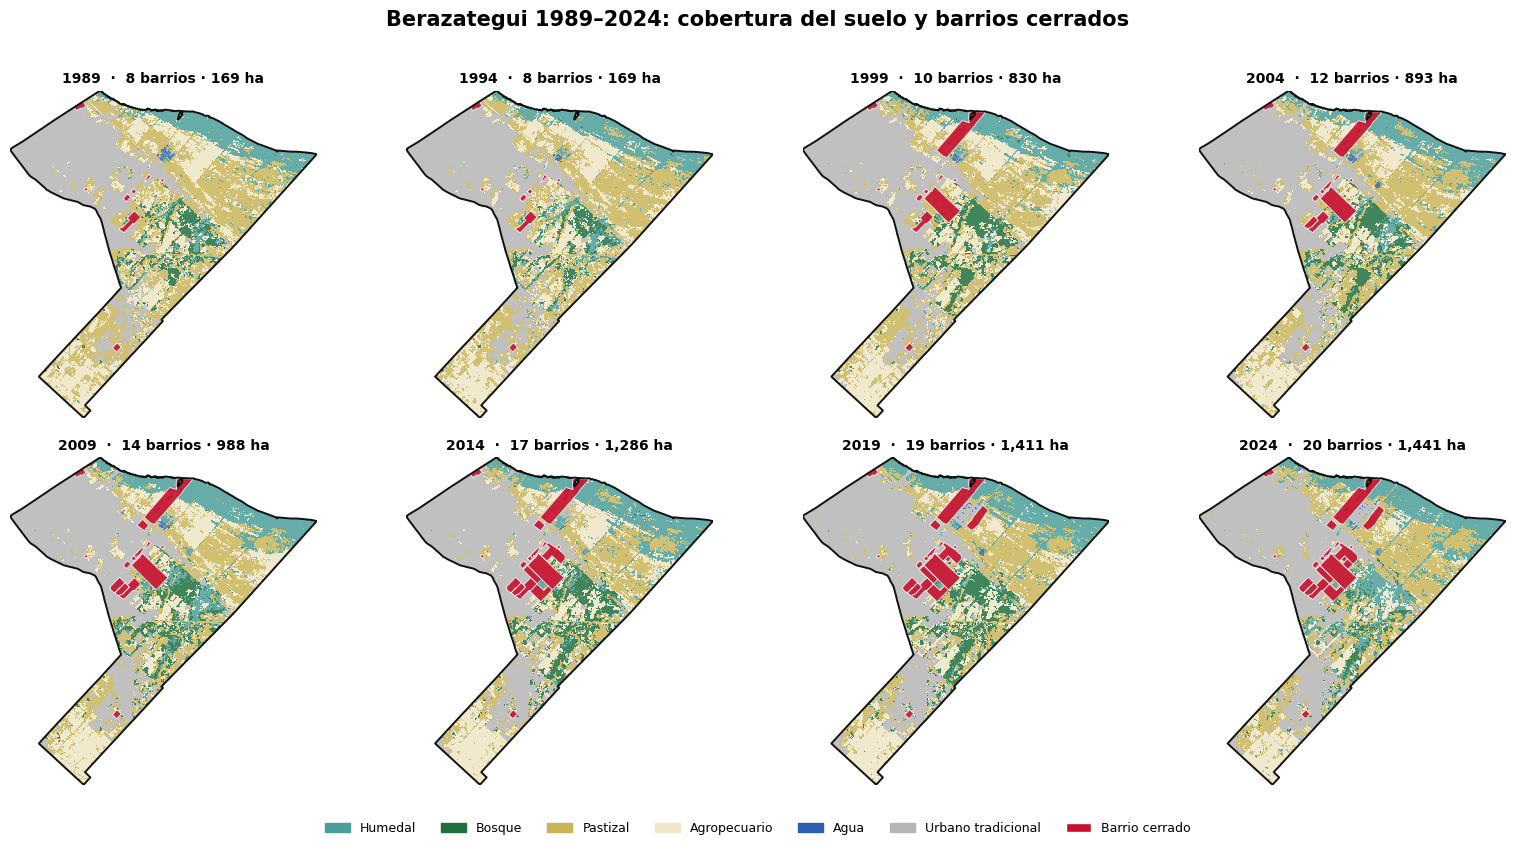

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, t in zip(axes.ravel(), range(len(anios_b))):
    b = mapa_anio(ax, t, etiquetas=False, fondo=False)
    ax.set_title(f"{anios_b[t]}  ·  {len(b)} barrios · {b['sup_ha'].sum():,.0f} ha", fontsize=10, fontweight="bold")
fig.legend(handles=LEYENDA_B, loc="lower center", ncol=7, frameon=False, fontsize=9)
fig.suptitle("Berazategui 1989–2024: cobertura del suelo y barrios cerrados", fontsize=15, fontweight="bold")
plt.tight_layout(rect=(0, 0.05, 1, 0.96))
plt.savefig(S / "figB1_paneles_quinquenales.png", dpi=200, bbox_inches="tight"); plt.show()

### B.2 Mapas de detalle: 1989, 2004 y 2024

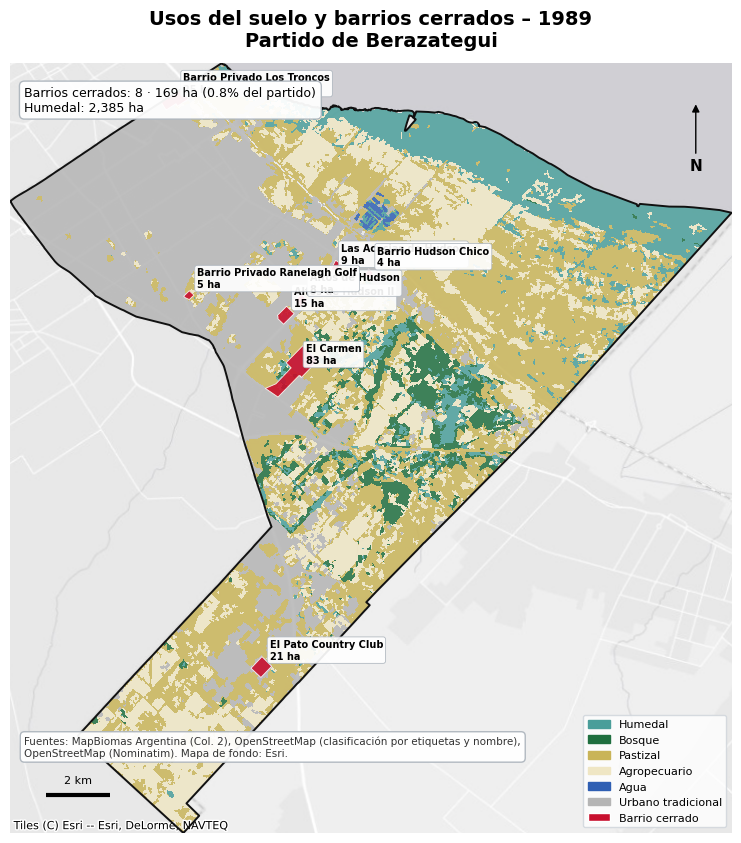

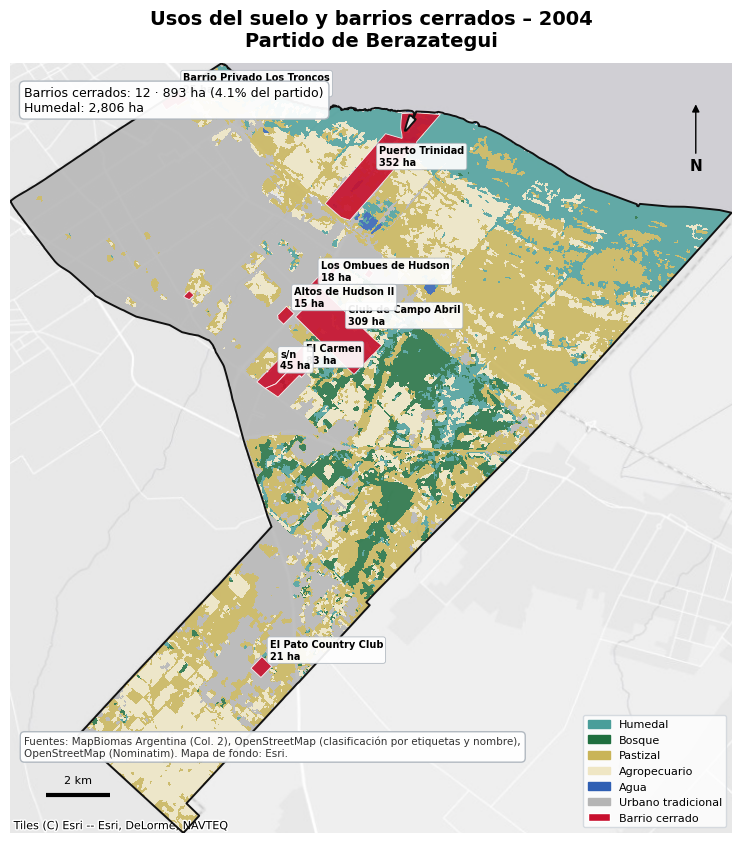

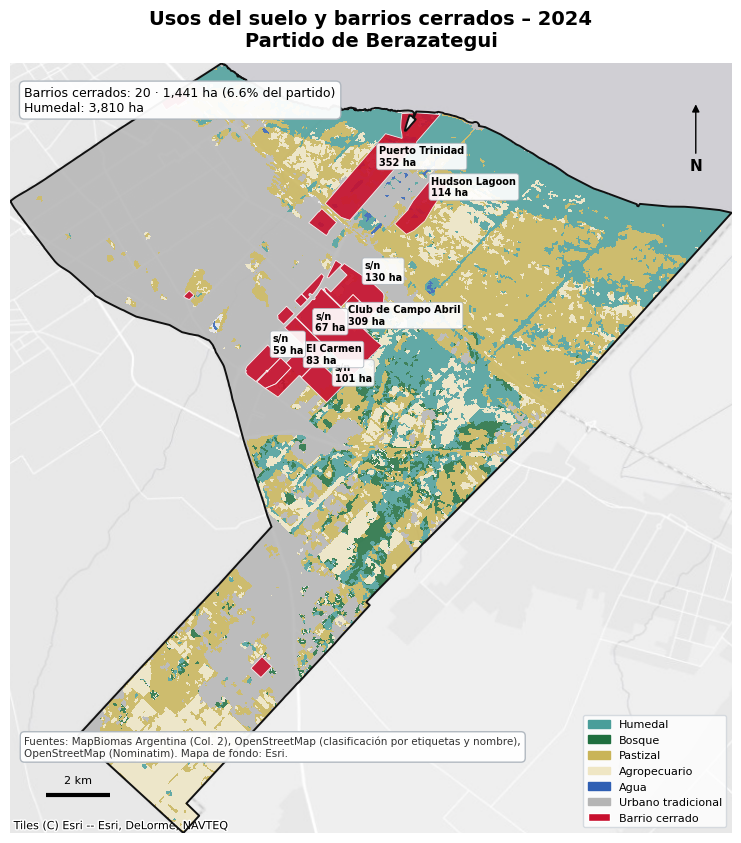

In [42]:
sup_partido = meta_b["sup_partido_ha"]
for anio in [1989, 2004, 2024]:
    t = anios_b.index(anio)
    fig, ax = plt.subplots(figsize=(10, 10), facecolor="white")
    b = mapa_anio(ax, t)
    escala_y_norte(ax)
    humedal_ha = np.nansum(capa_suelo(t) == CLASES_MAPA.index("Humedal")) * meta_b["res_m"] ** 2 / 1e4
    ax.set_title(f"Usos del suelo y barrios cerrados – {anio}\nPartido de Berazategui", fontsize=14, fontweight="bold", pad=12)
    ax.text(0.02, 0.97, f"Barrios cerrados: {len(b)} · {b['sup_ha'].sum():,.0f} ha ({b['sup_ha'].sum() / sup_partido:.1%} del partido)\n"
                        f"Humedal: {humedal_ha:,.0f} ha",
            transform=ax.transAxes, va="top", fontsize=9, zorder=8,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#adb5bd", alpha=0.95))
    ax.legend(handles=LEYENDA_B, loc="lower right", frameon=True, facecolor="white", edgecolor="#ced4da", fontsize=8)
    ax.text(0.02, 0.10, "Fuentes: MapBiomas Argentina (Col. 2), " + meta_b["fuente_barrios"] + ",\n"
                        + meta_b["fuente_limite"] + ". Mapa de fondo: Esri.",
            transform=ax.transAxes, fontsize=7.5, color="#333", zorder=8,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#adb5bd", alpha=0.95))
    plt.savefig(S / f"mapa_berazategui_{anio}.png", dpi=250, bbox_inches="tight"); plt.show()

# Parte C · Análisis

In [43]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from affine import Affine
from scipy.ndimage import distance_transform_edt

SALIDAS = Path("salidas")
meta = json.loads((SALIDAS / "metadatos.json").read_text(encoding="utf-8"))
z = np.load(SALIDAS / "mapbiomas_berazategui.npz")
CODIGOS, ANIOS, ID_BARRIO, DENTRO = z["codigos"], z["anios"].tolist(), z["id_barrio"], z["dentro"]
TRANSFORM = Affine(*z["transform"])
RES, HA_PIXEL = meta["res_m"], meta["res_m"] ** 2 / 10_000
GRUPOS = meta["grupos"]
IDX = {g: i for i, g in enumerate(GRUPOS)}
CODIGO_A_GRUPO = {int(k): v for k, v in meta["codigo_a_grupo"].items()}
CODIGOS_URBANOS = tuple(meta["codigos_urbanos"])
barrios = gpd.read_file(SALIDAS / "barrios_cerrados.gpkg")
limite = gpd.read_file(SALIDAS / "limite_partido.gpkg")

COLORES = {"Humedal": "#4a9e9a", "Bosque": "#1f6f3f", "Pastizal": "#c9b458", "Agropecuario": "#e8d9a8",
           "Agua": "#2f5fb3", "Urbano tradicional": "#9a9a9a", "Barrio cerrado": "#c8102e", "Otro": "#d9d9d9"}
SEMILLA, B = 2026, 1000
rng = np.random.default_rng(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(ANIOS)} cortes ({ANIOS[0]}–{ANIOS[-1]}), {len(barrios)} barrios, {DENTRO.sum() * HA_PIXEL:,.0f} ha")

8 cortes (1989–2024), 20 barrios, 21,818 ha


### Funciones del análisis
Son funciones puras de NumPy, sin dependencias geográficas, así que se pueden testear por separado.

In [44]:
NODATA = 255


def a_grupos(codigos, id_barrio, anio_barrio, anios, codigo_a_grupo, grupos):
    # Pasa los códigos MapBiomas a grupos de análisis. Desde el año de urbanización de cada barrio,
    # toda su huella (lagunas y parques incluidos) se clasifica como 'Barrio cerrado'.
    lut = np.full(256, grupos.index("Otro"), dtype=np.uint8)
    for cod, g in codigo_a_grupo.items():
        lut[cod] = grupos.index(g)
    lut[0] = NODATA
    G = lut[codigos]
    anio_px = np.full(id_barrio.shape, np.inf)
    hay = id_barrio > 0
    anio_px[hay] = np.asarray(anio_barrio, dtype=float)[id_barrio[hay] - 1]
    anio_px = np.nan_to_num(anio_px, nan=np.inf)          # barrios sin año detectado: no se reclasifican
    for t, a in enumerate(anios):
        G[t][(anio_px <= a) & (G[t] != NODATA)] = grupos.index("Barrio cerrado")
    return G


def matriz_transicion(g0, g1, n, mascara):
    v = mascara & (g0 != NODATA) & (g1 != NODATA)
    return np.bincount(g0[v].astype(np.int64) * n + g1[v], minlength=n * n).reshape(n, n)


def ids_bloque(forma, tam_px):
    filas, cols = np.indices(forma)
    return (filas // tam_px) * (int(np.ceil(forma[1] / tam_px))) + cols // tam_px


def conteos_por_bloque(g0, g1, n, mascara, bloques):
    v = mascara & (g0 != NODATA) & (g1 != NODATA)
    b_ids, b_inv = np.unique(bloques[v], return_inverse=True)
    idx = b_inv * n * n + g0[v].astype(np.int64) * n + g1[v]
    return np.bincount(idx, minlength=len(b_ids) * n * n).reshape(len(b_ids), n, n)


def a_probabilidades(conteos):
    filas = conteos.sum(axis=-1, keepdims=True)
    P = np.divide(conteos, filas, out=np.zeros(conteos.shape, dtype=float), where=filas > 0)
    vacias = filas[..., 0] == 0                           # clase ausente: se queda en su lugar
    if vacias.any():
        eye = np.broadcast_to(np.eye(conteos.shape[-1]), conteos.shape)
        P[vacias] = eye[vacias]
    return P


def markov_bootstrap(conteos_bloque, v0, pasos, B, rng):
    # Proyección v_{k+1} = v_k · P con incertidumbre por bootstrap de bloques espaciales.
    nb = conteos_bloque.shape[0]
    proy = np.empty((B, pasos + 1, len(v0)))
    for b in range(B):
        P = a_probabilidades(conteos_bloque[rng.integers(0, nb, nb)].sum(axis=0))
        v = np.asarray(v0, dtype=float)
        proy[b, 0] = v
        for k in range(pasos):
            v = v @ P
            proy[b, k + 1] = v
    return a_probabilidades(conteos_bloque.sum(axis=0)), proy


def bootstrap_composicion(conteos_unidad, B, rng):
    # conteos_unidad: (unidades, grupos). Remuestrea unidades (barrios o bloques) y devuelve proporciones.
    n = conteos_unidad.shape[0]
    tot = conteos_unidad.sum(axis=0)
    puntual = tot / max(tot.sum(), 1)
    boot = np.empty((B, conteos_unidad.shape[1]))
    for b in range(B):
        s = conteos_unidad[rng.integers(0, n, n)].sum(axis=0)
        boot[b] = s / max(s.sum(), 1)
    return puntual, np.percentile(boot, 5, axis=0), np.percentile(boot, 95, axis=0)


def resumen_ic(puntual, lo, hi, nombres):
    return pd.DataFrame({"Estimación": puntual, "IC90 inf": lo, "IC90 sup": hi}, index=nombres)

In [45]:
N = len(GRUPOS)
G = a_grupos(CODIGOS, ID_BARRIO, barrios["anio_urb"].to_numpy(), ANIOS, CODIGO_A_GRUPO, GRUPOS)
BLOQUES = ids_bloque(DENTRO.shape, tam_px=int(1000 / RES))    # bloques de ~1 km
sup = pd.DataFrame({a: np.bincount(G[t][DENTRO & (G[t] != NODATA)], minlength=N) * HA_PIXEL
                    for t, a in enumerate(ANIOS)}, index=GRUPOS)
sup.round(0)

,1989,1994,1999,2004,2009,2014,2019,2024
Humedal,2381.0,2676.0,2345.0,2731.0,3203.0,2910.0,2847.0,3754.0
Bosque,1031.0,893.0,1397.0,1369.0,1332.0,1645.0,1686.0,728.0
Pastizal,7002.0,6623.0,5601.0,5898.0,4863.0,4374.0,4865.0,5588.0
Agropecuario,4844.0,4836.0,4937.0,3994.0,4207.0,4197.0,3330.0,2582.0
Agua,46.0,22.0,20.0,38.0,24.0,9.0,40.0,31.0
Urbano tradicional,6300.0,6523.0,6639.0,6862.0,7167.0,7326.0,7548.0,7611.0
Barrio cerrado,170.0,170.0,829.0,893.0,988.0,1285.0,1410.0,1441.0
Otro,27.0,59.0,31.0,15.0,18.0,53.0,75.0,65.0


## 1. Cómo cambió el suelo del partido (EDA)

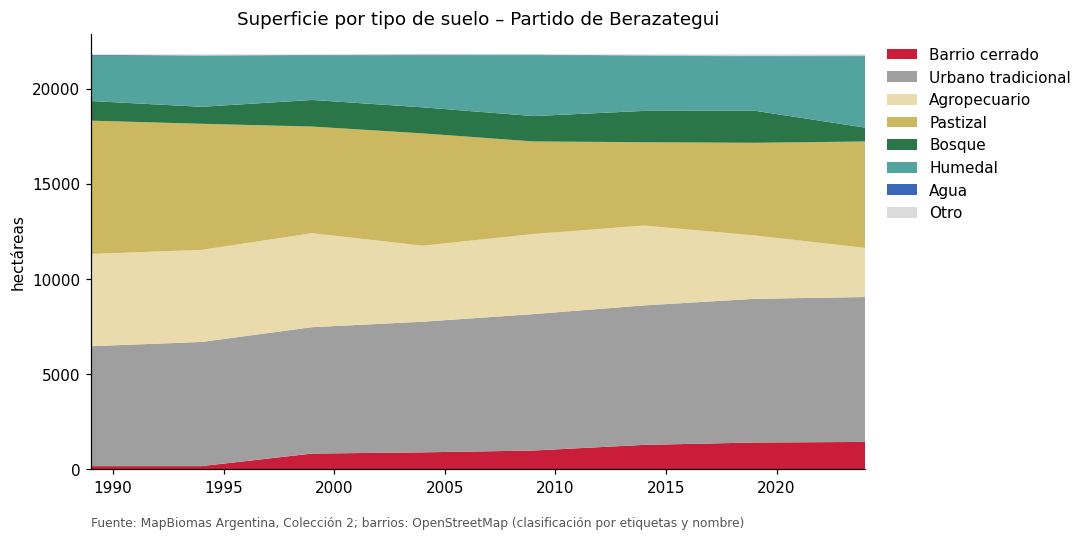

,1989,2024,Cambio 1989–2024 (ha)
Humedal,2381.0,3754.0,1373.0
Bosque,1031.0,728.0,-303.0
Pastizal,7002.0,5588.0,-1414.0
Agropecuario,4844.0,2582.0,-2262.0
Agua,46.0,31.0,-14.0
Urbano tradicional,6300.0,7611.0,1310.0
Barrio cerrado,170.0,1441.0,1272.0
Otro,27.0,65.0,38.0


In [46]:
fig, ax = plt.subplots(figsize=(10, 5))
orden = ["Barrio cerrado", "Urbano tradicional", "Agropecuario", "Pastizal", "Bosque", "Humedal", "Agua", "Otro"]
ax.stackplot(ANIOS, sup.loc[orden].to_numpy(), labels=orden, colors=[COLORES[g] for g in orden], alpha=0.95)
ax.set(title="Superficie por tipo de suelo – Partido de Berazategui", ylabel="hectáreas", xlim=(ANIOS[0], ANIOS[-1]))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.text(0, -0.13, "Fuente: MapBiomas Argentina, Colección 2; barrios: " + meta["fuente_barrios"],
        transform=ax.transAxes, fontsize=8, color="#555")
plt.tight_layout(); plt.savefig(SALIDAS / "fig1_superficie_por_tipo.png", dpi=200, bbox_inches="tight"); plt.show()

cambio = (sup[ANIOS[-1]] - sup[ANIOS[0]]).rename(f"Cambio {ANIOS[0]}–{ANIOS[-1]} (ha)")
pd.concat([sup[[ANIOS[0], ANIOS[-1]]], cambio], axis=1).round(0)

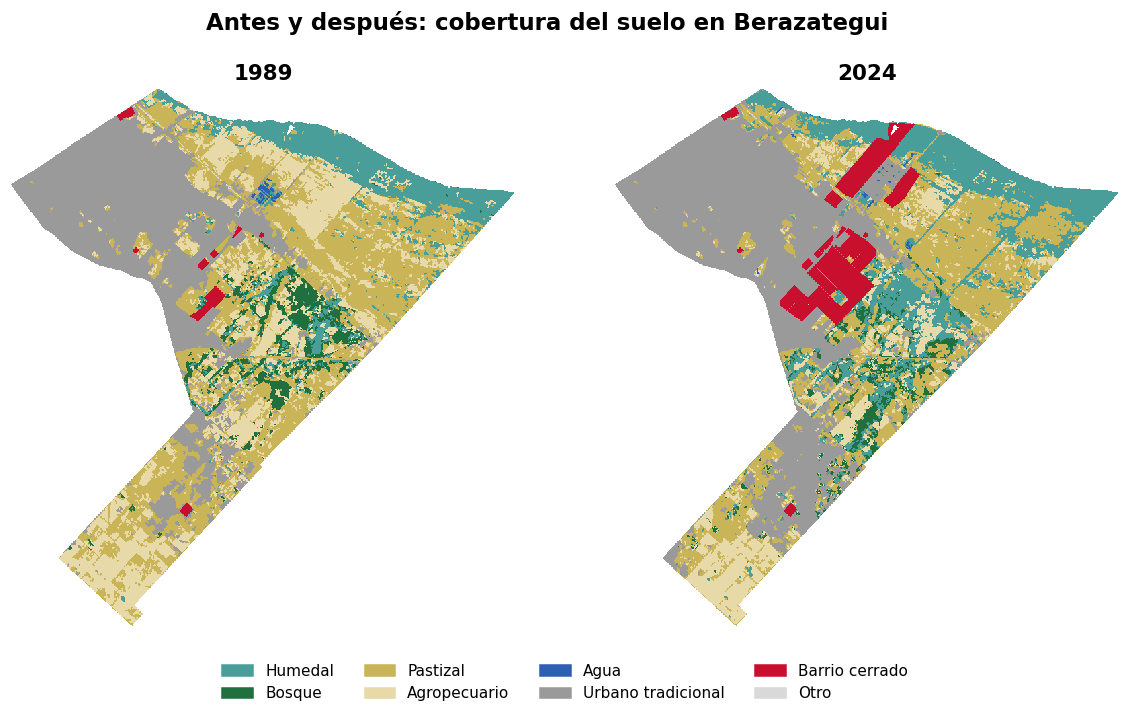

In [47]:
cmap = ListedColormap([COLORES[g] for g in GRUPOS])
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, t in zip(axes, [0, len(ANIOS) - 1]):
    img = np.ma.masked_where((G[t] == NODATA) | ~DENTRO, G[t])
    ax.imshow(img, cmap=cmap, vmin=-0.5, vmax=N - 0.5, interpolation="nearest")
    ax.set_title(str(ANIOS[t]), fontsize=14, fontweight="bold"); ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORES[g]) for g in GRUPOS]
fig.legend(handles, GRUPOS, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Antes y después: cobertura del suelo en Berazategui", fontsize=15, fontweight="bold")
plt.savefig(SALIDAS / "fig2_antes_despues.png", dpi=200, bbox_inches="tight"); plt.show()

## 2. Qué se transformó en qué: matriz de transición
Cada fila indica qué porcentaje de una clase en el año inicial terminó en cada clase en el año final. La diagonal muestra lo que se mantuvo igual.

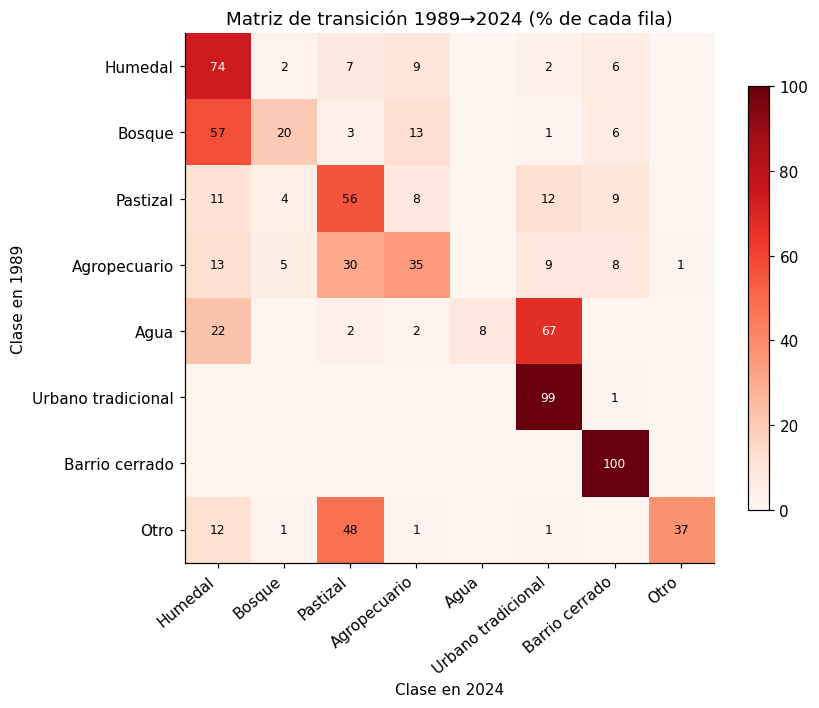

In [48]:
T = matriz_transicion(G[0], G[-1], N, DENTRO)
pct = pd.DataFrame(a_probabilidades(T) * 100, index=GRUPOS, columns=GRUPOS)
activas = [g for g in GRUPOS if T[IDX[g]].sum() + T[:, IDX[g]].sum() > 0]
pct = pct.loc[activas, activas]

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(pct.to_numpy(), cmap="Reds", vmin=0, vmax=100)
ax.set_xticks(range(len(activas)), activas, rotation=40, ha="right"); ax.set_yticks(range(len(activas)), activas)
for i in range(len(activas)):
    for j in range(len(activas)):
        v = pct.iat[i, j]
        if v >= 0.5:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "black")
ax.set(xlabel=f"Clase en {ANIOS[-1]}", ylabel=f"Clase en {ANIOS[0]}", title=f"Matriz de transición {ANIOS[0]}→{ANIOS[-1]} (% de cada fila)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.savefig(SALIDAS / "fig3_matriz_transicion.png", dpi=200, bbox_inches="tight"); plt.show()

In [49]:
import plotly.graph_objects as go

# Sankey: solo los cambios (fuera de la diagonal), para ver de dónde sale el suelo urbanizado
src, dst, val = [], [], []
for i in range(N):
    for j in range(N):
        if i != j and T[i, j] * HA_PIXEL >= 5:          # flujos ≥ 5 ha
            src.append(i); dst.append(N + j); val.append(round(T[i, j] * HA_PIXEL, 1))
hex_rgba = lambda h, a: f"rgba({int(h[1:3], 16)},{int(h[3:5], 16)},{int(h[5:7], 16)},{a})"
fig = go.Figure(go.Sankey(
    node=dict(label=[f"{g} {ANIOS[0]}" for g in GRUPOS] + [f"{g} {ANIOS[-1]}" for g in GRUPOS],
              color=[COLORES[g] for g in GRUPOS] * 2, pad=14, thickness=16),
    link=dict(source=src, target=dst, value=val, color=[hex_rgba(COLORES[GRUPOS[s]], 0.45) for s in src])))
fig.update_layout(title=f"Cambios de uso del suelo {ANIOS[0]}→{ANIOS[-1]} (hectáreas)", font_size=12, height=520)
fig.write_html(SALIDAS / "fig4_sankey.html")
fig.show()

## 3. Qué suelo reemplazan los barrios cerrados frente al urbano tradicional

Para cada barrio se toma el **suelo del último corte anterior a su urbanización**. Se excluyen los barrios ya urbanizados en 1989, porque su suelo previo no se observa. Se compara con el suelo que reemplazó el **crecimiento urbano tradicional** (píxeles que pasaron a urbano fuera de los barrios) en los mismos períodos.

- Los intervalos de los barrios remuestrean **barrios**.
- Los del urbano tradicional remuestrean **bloques de 1 km**.

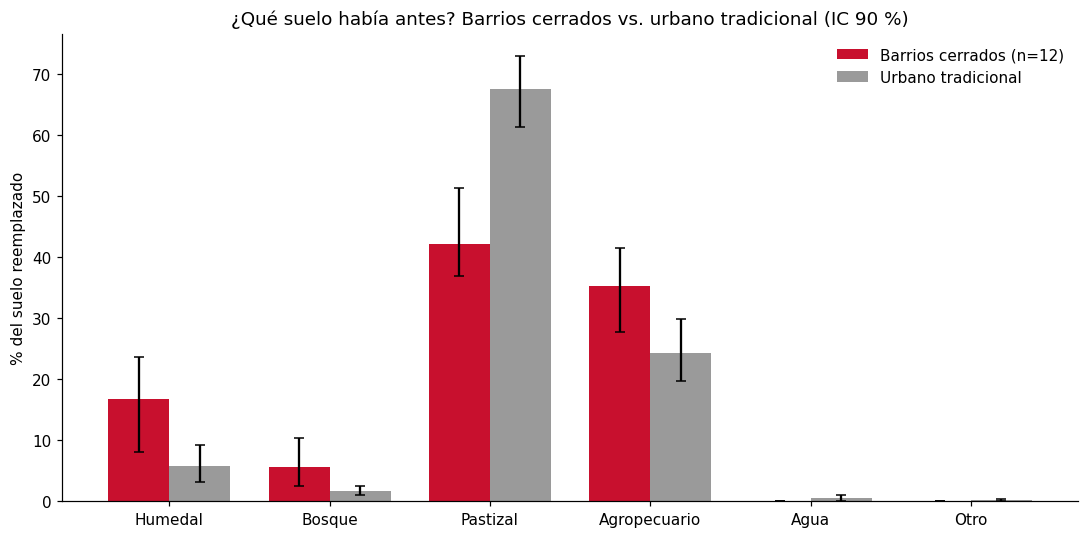

Barrios cerrados                   Urbano tradicional           \
                   Estimación IC90 inf IC90 sup         Estimación IC90 inf   
Humedal                  16.8      8.1     23.6                5.8      3.2   
Bosque                    5.7      2.5     10.3                1.7      1.0   
Pastizal                 42.1     36.9     51.2               67.5     61.4   
Agropecuario             35.3     27.8     41.4               24.3     19.7   
Agua                      0.0      0.0      0.0                0.5      0.1   
Otro                      0.0      0.0      0.1                0.2      0.1   

                       
             IC90 sup  
Humedal           9.2  
Bosque            2.5  
Pastizal         72.9  
Agropecuario     29.9  
Agua              1.0  
Otro              0.4

In [50]:
def suelo_previo_barrios(G, id_barrio, anio_barrio, anios, n):
    filas = []
    for b, a in enumerate(anio_barrio):
        if not np.isfinite(a) or a == anios[0]:
            continue
        t_prev = anios.index(int(a)) - 1
        g = G[t_prev][(id_barrio == b + 1) & (G[t_prev] != NODATA)]
        filas.append(np.bincount(g, minlength=n))
    return np.array(filas).reshape(-1, n)


def suelo_previo_urbano(G, dentro, bloques, n, idx_urb):
    acum = {}
    for t in range(1, G.shape[0]):
        nuevo = dentro & (G[t] == idx_urb) & (G[t - 1] != idx_urb) & (G[t - 1] != NODATA)
        b_ids, inv = np.unique(bloques[nuevo], return_inverse=True)
        c = np.bincount(inv * n + G[t - 1][nuevo], minlength=len(b_ids) * n).reshape(-1, n)
        for bid, fila in zip(b_ids, c):
            acum[bid] = acum.get(bid, 0) + fila
    return np.array(list(acum.values())).reshape(-1, n)


cb = suelo_previo_barrios(G, ID_BARRIO, barrios["anio_urb"].to_numpy(), ANIOS, N)
cu = suelo_previo_urbano(G, DENTRO, BLOQUES, N, IDX["Urbano tradicional"])
NATURALES = ["Humedal", "Bosque", "Pastizal", "Agropecuario", "Agua", "Otro"]
sel = [IDX[g] for g in NATURALES]
rb = resumen_ic(*bootstrap_composicion(cb[:, sel], B, rng), NATURALES)
ru = resumen_ic(*bootstrap_composicion(cu[:, sel], B, rng), NATURALES)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(NATURALES)); w = 0.38
for k, (r, nom, col) in enumerate([(rb, f"Barrios cerrados (n={len(cb)})", COLORES["Barrio cerrado"]),
                                   (ru, "Urbano tradicional", COLORES["Urbano tradicional"])]):
    ax.bar(x + (k - 0.5) * w, r["Estimación"] * 100, w, color=col, label=nom,
           yerr=[(r["Estimación"] - r["IC90 inf"]) * 100, (r["IC90 sup"] - r["Estimación"]) * 100], capsize=3)
ax.set_xticks(x, NATURALES); ax.set_ylabel("% del suelo reemplazado")
ax.set_title("¿Qué suelo había antes? Barrios cerrados vs. urbano tradicional (IC 90 %)")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(SALIDAS / "fig5_suelo_reemplazado.png", dpi=200, bbox_inches="tight"); plt.show()

comparacion = pd.concat({"Barrios cerrados": rb, "Urbano tradicional": ru}, axis=1).mul(100).round(1)
comparacion

## 4. Exposición: urbanización sobre ex-humedal o agua

Como indicador del riesgo de inundación, se toma la superficie urbanizada (barrio cerrado o urbano tradicional) que **en 1989 era humedal o agua**. Es el equivalente a medir cuántas sumas aseguradas se acumulan en una zona de peligro.

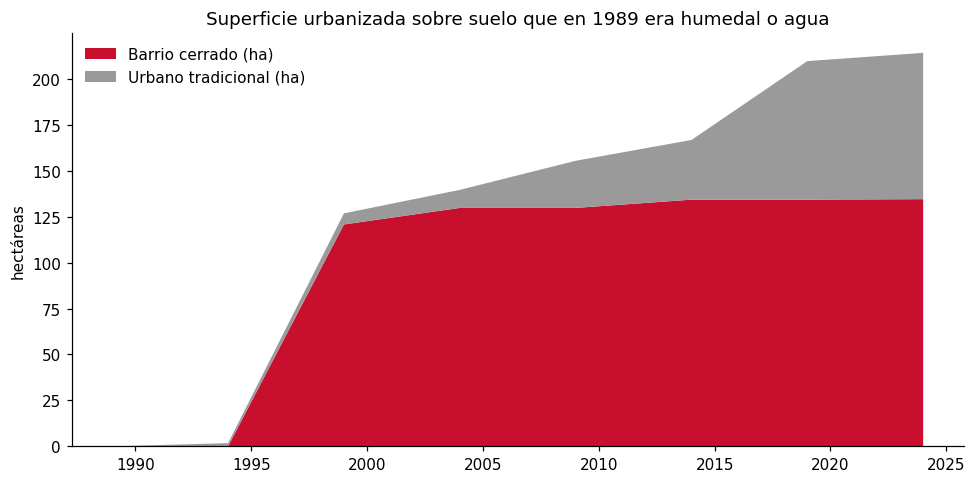

,Barrio cerrado (ha),Urbano tradicional (ha),% del ex-humedal urbanizado
1989,0.0,0.0,0.0
1994,0.0,1.7,0.1
1999,120.8,6.0,5.2
2004,129.8,9.8,5.8
2009,129.8,25.6,6.4
2014,134.3,32.5,6.9
2019,134.3,75.4,8.6
2024,134.5,79.6,8.8


In [51]:
ex_humedo = np.isin(G[0], [IDX["Humedal"], IDX["Agua"]]) & DENTRO
expo = pd.DataFrame({
    "Barrio cerrado (ha)": [((G[t] == IDX["Barrio cerrado"]) & ex_humedo).sum() * HA_PIXEL for t in range(len(ANIOS))],
    "Urbano tradicional (ha)": [((G[t] == IDX["Urbano tradicional"]) & ex_humedo).sum() * HA_PIXEL for t in range(len(ANIOS))],
}, index=ANIOS)
expo["% del ex-humedal urbanizado"] = expo.sum(axis=1) / (ex_humedo.sum() * HA_PIXEL) * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.stackplot(ANIOS, expo.iloc[:, 0], expo.iloc[:, 1], colors=[COLORES["Barrio cerrado"], COLORES["Urbano tradicional"]],
             labels=expo.columns[:2])
ax.set(title="Superficie urbanizada sobre suelo que en 1989 era humedal o agua", ylabel="hectáreas")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); plt.savefig(SALIDAS / "fig6_exposicion.png", dpi=200, bbox_inches="tight"); plt.show()
expo.round(1)

## 5. Proyección a 2034 con cadena de Markov

La matriz de transición de 5 años funciona como una **tabla de decrementos**: da la probabilidad de que una hectárea de cada clase pase a otra en el período. Se estima con los dos últimos períodos (2014→2019 y 2019→2024) y se proyecta dos pasos, a 2029 y 2034. La banda de confianza sale de remuestrear bloques espaciales.

**Supuesto principal:** las probabilidades de transición se mantienen constantes, es decir, el proceso es homogéneo en el tiempo. Es una proyección de tendencia, no un pronóstico.

In [52]:
def conteos_periodos(periodos):
    # Suma los conteos de varios períodos alineando los bloques por su id.
    ids_todos = np.unique(BLOQUES[DENTRO])
    total = np.zeros((len(ids_todos), N, N), dtype=np.int64)
    pos = {b: i for i, b in enumerate(ids_todos)}
    for t in periodos:
        v = DENTRO & (G[t] != NODATA) & (G[t + 1] != NODATA)
        idx = np.array([pos[b] for b in np.unique(BLOQUES[v])])
        total[idx] += conteos_por_bloque(G[t], G[t + 1], N, DENTRO, BLOQUES)
    return total

conteos = conteos_periodos([len(ANIOS) - 3, len(ANIOS) - 2])
v0 = np.bincount(G[-1][DENTRO & (G[-1] != NODATA)], minlength=N) * HA_PIXEL
P, proy = markov_bootstrap(conteos, v0, pasos=2, B=B, rng=rng)
anios_proy = [ANIOS[-1], ANIOS[-1] + 5, ANIOS[-1] + 10]

pd.DataFrame(P * 100, index=GRUPOS, columns=GRUPOS).round(1).style.set_caption("Probabilidad de transición a 5 años (%)")

,Humedal,Bosque,Pastizal,Agropecuario,Agua,Urbano tradicional,Barrio cerrado,Otro
Humedal,79.900000,3.300000,11.700000,3.800000,0.500000,0.600000,0.000000,0.200000
Bosque,29.000000,58.200000,4.600000,6.000000,0.000000,0.400000,0.100000,1.600000
Pastizal,6.100000,1.300000,84.100000,5.700000,0.100000,1.800000,0.700000,0.200000
Agropecuario,6.000000,1.700000,24.300000,65.800000,0.100000,1.000000,1.000000,0.200000
Agua,26.200000,0.000000,2.800000,0.000000,57.100000,11.600000,0.000000,2.400000
Urbano tradicional,0.000000,0.000000,0.000000,0.000000,0.000000,99.900000,0.100000,0.000000
Barrio cerrado,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000,0.000000
Otro,8.100000,31.100000,21.000000,6.500000,1.100000,1.300000,0.000000,30.900000


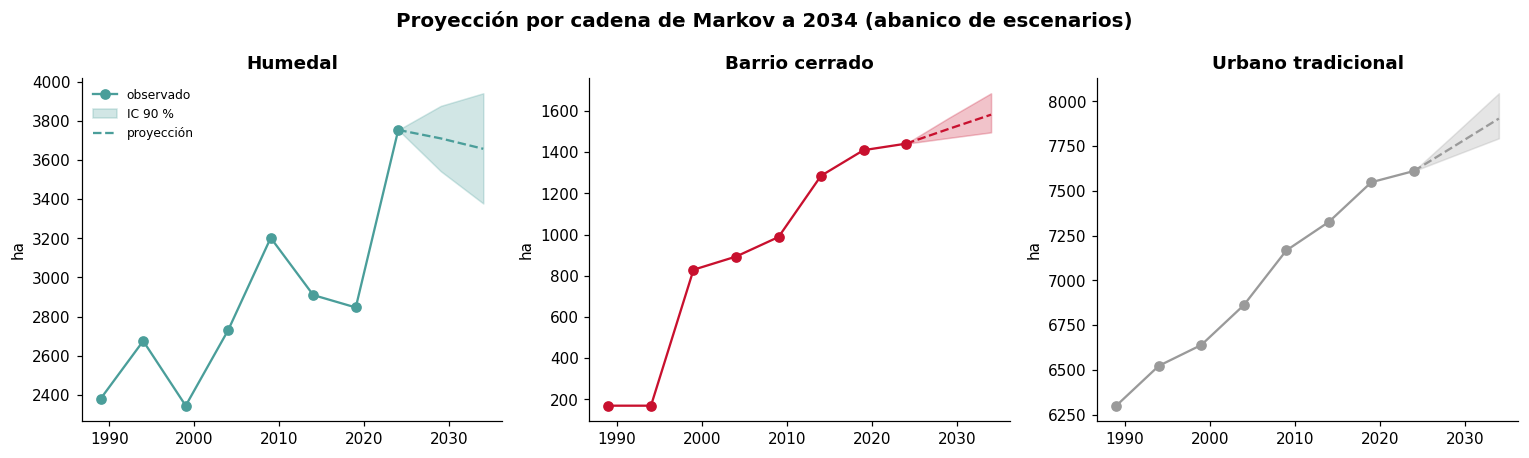

,2024 – mediana,2029 – mediana,2034 – mediana,2034 – IC90
Humedal,3754.0,3710.0,3657.0,"3,378 – 3,941"
Bosque,728.0,687.0,656.0,560 – 751
Pastizal,5588.0,5817.0,5911.0,"5,611 – 6,224"
Agropecuario,2582.0,2208.0,1969.0,"1,784 – 2,175"
Agua,31.0,43.0,50.0,34 – 71
Urbano tradicional,7611.0,7757.0,7904.0,"7,793 – 8,045"
Barrio cerrado,1441.0,1513.0,1582.0,"1,496 – 1,686"
Otro,65.0,57.0,53.0,40 – 72


In [53]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
for ax, g in zip(axes, ["Humedal", "Barrio cerrado", "Urbano tradicional"]):
    i = IDX[g]
    ax.plot(ANIOS, sup.loc[g], "o-", color=COLORES[g], label="observado")
    q = np.percentile(proy[:, :, i], [5, 50, 95], axis=0)
    ax.fill_between(anios_proy, q[0], q[2], color=COLORES[g], alpha=0.25, label="IC 90 %")
    ax.plot(anios_proy, q[1], "--", color=COLORES[g], label="proyección")
    ax.set_title(g, fontweight="bold"); ax.set_ylabel("ha")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Proyección por cadena de Markov a 2034 (abanico de escenarios)", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(SALIDAS / "fig7_markov_2034.png", dpi=200, bbox_inches="tight"); plt.show()

tabla_proy = pd.DataFrame({
    f"{a} – mediana": np.median(proy[:, k], axis=0) for k, a in enumerate(anios_proy)
} | {
    f"{anios_proy[-1]} – IC90": [f"{lo:,.0f} – {hi:,.0f}" for lo, hi in zip(*np.percentile(proy[:, -1], [5, 95], axis=0))]
}, index=GRUPOS)
tabla_proy.round(0)

## 6. ¿Dónde es más probable el próximo barrio cerrado? Regresión logística

Es un modelo del mismo tipo que los de tarificación (GLM binomial). La unidad es el **píxel no urbano en 2004**, y la variable respuesta indica si **pasó a barrio cerrado antes de 2024**. Las variables explicativas son:

- **Distancias (en km) estandarizadas:** a la mancha urbana, al agua (río o arroyos) y a barrios cerrados existentes, todas medidas en 2004.
- **Clase de suelo en 2004:** codificada *one-hot*, con *Agropecuario* como categoría de referencia.

Los errores estándar están **agrupados por bloque de 1 km**, para tener en cuenta la correlación espacial. Los resultados se informan como *odds ratio* por cada desvío estándar.

In [54]:
import statsmodels.api as sm

t0, t1 = ANIOS.index(2004), len(ANIOS) - 1
g0 = G[t0]
dist_km = lambda m: distance_transform_edt(~m) * RES / 1000
X_dist = {
    "dist_urbano": dist_km(g0 == IDX["Urbano tradicional"]),
    "dist_agua": dist_km(g0 == IDX["Agua"]),
    "dist_barrio": dist_km(g0 == IDX["Barrio cerrado"]) if (g0 == IDX["Barrio cerrado"]).any() else None,
}
X_dist = {k: v for k, v in X_dist.items() if v is not None}

candidato = DENTRO & np.isin(g0, [IDX[g] for g in ["Humedal", "Bosque", "Pastizal", "Agropecuario"]])
y_full = (G[t1] == IDX["Barrio cerrado"])

pix = np.flatnonzero(candidato.ravel())
pix = rng.choice(pix, size=min(300_000, pix.size), replace=False)
df = pd.DataFrame({k: v.ravel()[pix] for k, v in X_dist.items()})
medias, desvios = df.mean(), df.std()
df = (df - medias) / desvios                                   # escalado: coeficientes comparables
clase0 = pd.Categorical([GRUPOS[c] for c in g0.ravel()[pix]], categories=["Agropecuario", "Humedal", "Bosque", "Pastizal"])
df = df.join(pd.get_dummies(clase0, prefix="suelo", drop_first=True).astype(float).set_index(df.index))
y = y_full.ravel()[pix].astype(int)
grupos_cluster = BLOQUES.ravel()[pix]
print(f"Píxeles en la muestra: {len(y):,} | conversiones a barrio cerrado: {y.sum():,}")
assert y.sum() >= 30, "Muy pocas conversiones para estimar el modelo con estabilidad"

modelo = sm.Logit(y, sm.add_constant(df)).fit(disp=0, cov_type="cluster", cov_kwds={"groups": grupos_cluster})
ic = modelo.conf_int()
OR = pd.DataFrame({"Odds ratio": np.exp(modelo.params), "IC95 inf": np.exp(ic[0]), "IC95 sup": np.exp(ic[1]),
                   "p-valor": modelo.pvalues}).drop(index="const")
OR.round(3)

Píxeles en la muestra: 155,474 | conversiones a barrio cerrado: 5,608


,Odds ratio,IC95 inf,IC95 sup,p-valor
dist_urbano,0.078,0.016,0.377,0.002
dist_agua,0.502,0.294,0.857,0.012
dist_barrio,0.018,0.003,0.107,0.000
suelo_Humedal,0.132,0.039,0.444,0.001
suelo_Bosque,2.455,0.860,7.011,0.093
suelo_Pastizal,0.981,0.491,1.958,0.956


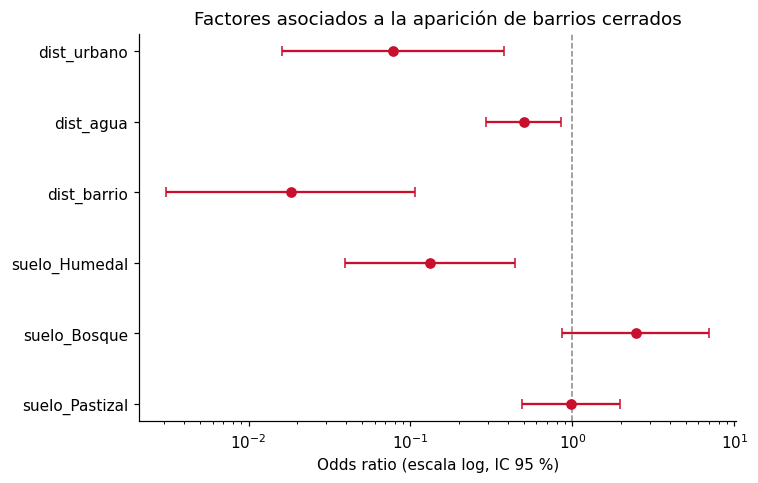

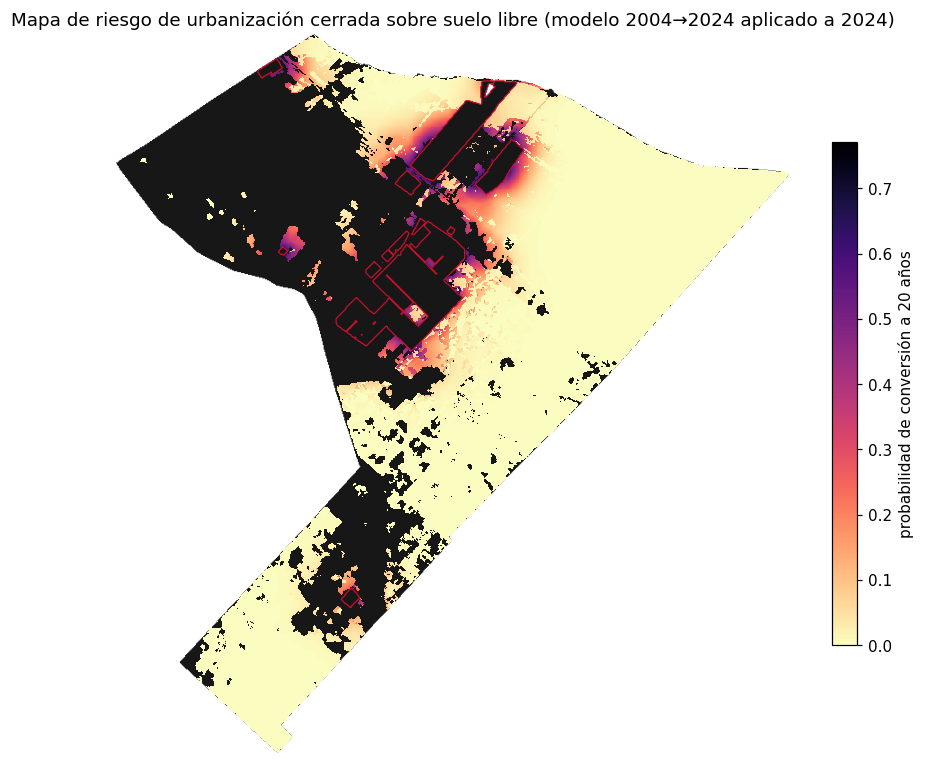

In [55]:
fig, ax = plt.subplots(figsize=(7, 0.5 * len(OR) + 1.5))
yy = np.arange(len(OR))[::-1]
ax.errorbar(OR["Odds ratio"], yy, xerr=[OR["Odds ratio"] - OR["IC95 inf"], OR["IC95 sup"] - OR["Odds ratio"]],
            fmt="o", color=COLORES["Barrio cerrado"], capsize=3)
ax.axvline(1, color="#888", lw=1, ls="--")
ax.set_xscale("log"); ax.set_yticks(yy, OR.index)
ax.set(xlabel="Odds ratio (escala log, IC 95 %)", title="Factores asociados a la aparición de barrios cerrados")
plt.tight_layout(); plt.savefig(SALIDAS / "fig8_odds_ratio.png", dpi=200, bbox_inches="tight"); plt.show()

# Mapa de probabilidad para el suelo que hoy sigue libre (aplicando el modelo a las condiciones de 2024)
g_hoy = G[t1]
libre = DENTRO & np.isin(g_hoy, [IDX[g] for g in ["Humedal", "Bosque", "Pastizal", "Agropecuario"]])
X_hoy = {"dist_urbano": dist_km(g_hoy == IDX["Urbano tradicional"]), "dist_agua": dist_km(g_hoy == IDX["Agua"]),
         "dist_barrio": dist_km(g_hoy == IDX["Barrio cerrado"])}
dh = pd.DataFrame({k: X_hoy[k][libre] for k in X_dist}); dh = (dh - medias) / desvios
cl = pd.Categorical([GRUPOS[c] for c in g_hoy[libre]], categories=clase0.categories)
dh = dh.join(pd.get_dummies(cl, prefix="suelo", drop_first=True).astype(float).set_index(dh.index))
prob = np.full(DENTRO.shape, np.nan); prob[libre] = modelo.predict(sm.add_constant(dh, has_constant="add")[modelo.params.index])

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(np.where(DENTRO, 0.92, np.nan), cmap="Greys", vmin=0, vmax=1)
im = ax.imshow(prob, cmap="magma_r", interpolation="nearest")
ax.contour(G[t1] == IDX["Barrio cerrado"], levels=[0.5], colors=COLORES["Barrio cerrado"], linewidths=0.8)
ax.axis("off"); plt.colorbar(im, ax=ax, shrink=0.7, label="probabilidad de conversión a 20 años")
ax.set_title("Mapa de riesgo de urbanización cerrada sobre suelo libre (modelo 2004→2024 aplicado a 2024)")
plt.tight_layout(); plt.savefig(SALIDAS / "fig9_mapa_probabilidad.png", dpi=200, bbox_inches="tight"); plt.show()

## 6b. ¿La pérdida de suelo natural forma clusters? Moran's I y LISA

La unidad de análisis es el **bloque de 1 km**. Para cada bloque se calcula qué parte de su suelo natural de 1989 (humedal, bosque, pastizal) estaba urbanizada en 2024.

- **Moran's I global:** dice si los bloques con mucha pérdida tienden a estar al lado de otros iguales. Si es así, hay un patrón espacial y no un fenómeno al azar.
- **LISA:** ubica *dónde* están esos clusters (Alto-Alto = punto caliente).

Se usan vecinos tipo torre (los bloques que comparten un lado), y los p-valores salen de 999 permutaciones.

In [56]:
TAM = int(1000 / RES)
NRB, NCB = int(np.ceil(DENTRO.shape[0] / TAM)), int(np.ceil(DENTRO.shape[1] / TAM))


def por_bloque(valores):
    return np.bincount(BLOQUES[DENTRO], weights=np.asarray(valores, dtype=float)[DENTRO],
                       minlength=NRB * NCB).reshape(NRB, NCB)


def pesos_torre(valido):
    idx = -np.ones(valido.shape, dtype=int)
    idx[valido] = np.arange(valido.sum())
    pares = []
    for di, dj in [(0, 1), (1, 0)]:
        a, b = idx[:valido.shape[0] - di, :valido.shape[1] - dj], idx[di:, dj:]
        m = (a >= 0) & (b >= 0)
        pares.append(np.c_[a[m], b[m]])
    p = np.vstack(pares)
    W = np.zeros((valido.sum(), valido.sum()))
    W[p[:, 0], p[:, 1]] = W[p[:, 1], p[:, 0]] = 1
    fila = W.sum(axis=1, keepdims=True)
    return np.divide(W, fila, out=np.zeros_like(W), where=fila > 0)


def moran_global(x, W, perms, rng):
    def I(v):
        z = v - v.mean()
        return (len(z) / W.sum()) * (z @ W @ z) / (z @ z)
    obs = I(x)
    sims = np.array([I(rng.permutation(x)) for _ in range(perms)])
    return obs, (np.sum(sims >= obs) + 1) / (perms + 1), sims


def lisa(x, W, perms, rng):
    z = (x - x.mean()) / x.std()
    lag = W @ z
    Ii = z * lag
    extremos = np.zeros(len(z))
    for _ in range(perms):
        Ip = z * (W @ rng.permutation(z))
        extremos += np.where(Ii >= 0, Ip >= Ii, Ip <= Ii)
    p = (extremos + 1) / (perms + 1)
    cuadrante = np.select([(z > 0) & (lag > 0), (z < 0) & (lag < 0), (z > 0) & (lag < 0), (z < 0) & (lag > 0)],
                          ["Alto-Alto", "Bajo-Bajo", "Alto-Bajo", "Bajo-Alto"], "—")
    return z, lag, p, cuadrante


natural0 = np.isin(G[0], [IDX[g] for g in ["Humedal", "Bosque", "Pastizal"]])
urbano_fin = np.isin(G[-1], [IDX["Urbano tradicional"], IDX["Barrio cerrado"]])
n_px, n_nat = por_bloque(np.ones(DENTRO.shape)), por_bloque(natural0)
VALIDO = (n_px >= 0.5 * TAM * TAM) & (n_nat >= 20)
perdida_bloque = por_bloque(natural0 & urbano_fin)[VALIDO] / n_nat[VALIDO]
W_torre = pesos_torre(VALIDO)

I_obs, p_I, sims_I = moran_global(perdida_bloque, W_torre, 999, rng)
z_l, lag_l, p_l, cuad_l = lisa(perdida_bloque, W_torre, 999, rng)
print(f"Bloques analizados: {VALIDO.sum()} | Moran's I = {I_obs:.3f} (p = {p_I:.3f})")
pd.Series(np.where(p_l < 0.05, cuad_l, "No significativo")).value_counts().rename("Bloques por tipo de cluster")

Bloques analizados: 200 | Moran's I = 0.723 (p = 0.001)


,Bloques por tipo de cluster
No significativo,133
Bajo-Bajo,34
Alto-Alto,32
Bajo-Alto,1


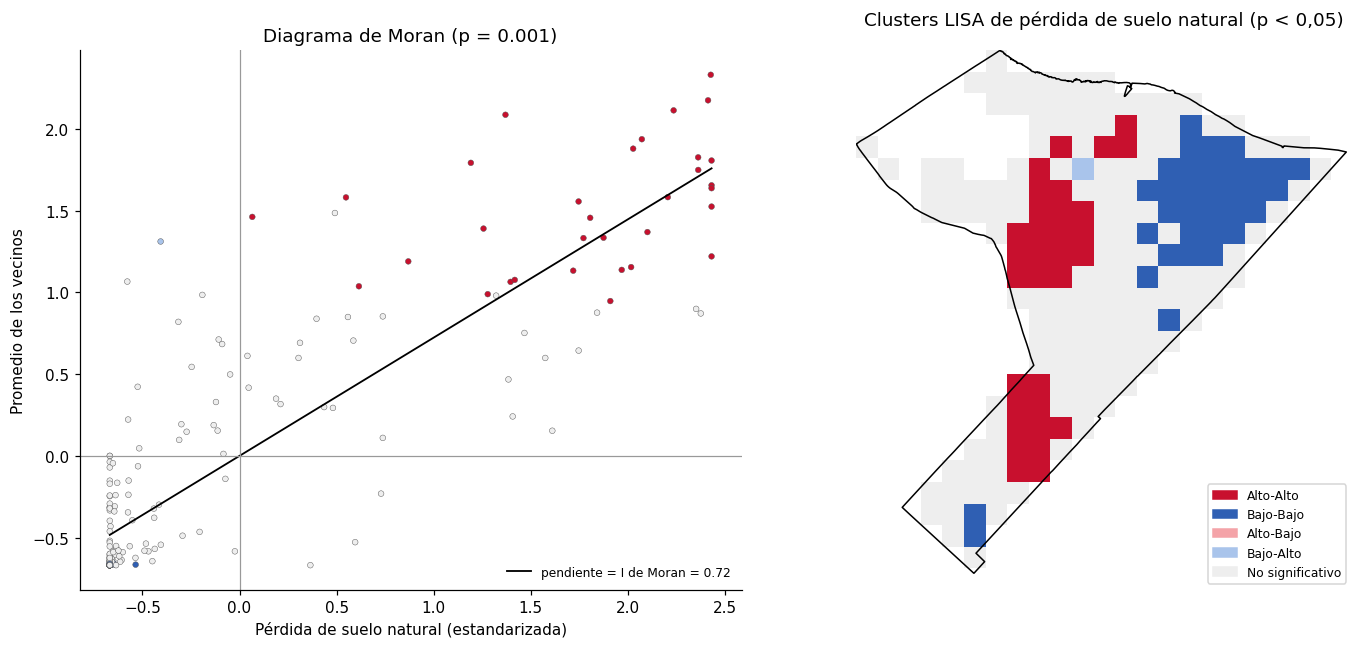

In [57]:
COL_LISA = {"Alto-Alto": "#c8102e", "Bajo-Bajo": "#2f5fb3", "Alto-Bajo": "#f4a3a8", "Bajo-Alto": "#a9c4eb",
            "No significativo": "#eeeeee"}
cat = np.where(p_l < 0.05, cuad_l, "No significativo")
orden_l = list(COL_LISA)
grilla = np.full(VALIDO.shape, np.nan)
grilla[VALIDO] = [orden_l.index(c) for c in cat]
ext_b = (TRANSFORM.c, TRANSFORM.c + NCB * TAM * RES, TRANSFORM.f - NRB * TAM * RES, TRANSFORM.f)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.25]})
a1.scatter(z_l, lag_l, s=14, c=[COL_LISA[c] for c in cat], edgecolor="#555", linewidth=0.3)
xs = np.linspace(z_l.min(), z_l.max(), 2)
a1.plot(xs, I_obs * xs, color="k", lw=1.2, label=f"pendiente = I de Moran = {I_obs:.2f}")
a1.axhline(0, color="#999", lw=0.8); a1.axvline(0, color="#999", lw=0.8)
a1.set(xlabel="Pérdida de suelo natural (estandarizada)", ylabel="Promedio de los vecinos",
       title=f"Diagrama de Moran (p = {p_I:.3f})"); a1.legend(frameon=False, fontsize=8)
a2.imshow(grilla, extent=ext_b, cmap=ListedColormap(list(COL_LISA.values())), vmin=-0.5, vmax=len(orden_l) - 0.5,
          interpolation="nearest")
limite.boundary.plot(ax=a2, color="k", linewidth=1)
a2.set_axis_off(); a2.set_title("Clusters LISA de pérdida de suelo natural (p < 0,05)")
a2.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COL_LISA.values()], labels=orden_l,
          loc="lower right", frameon=True, fontsize=8)
plt.tight_layout(); plt.savefig(SALIDAS / "fig10_moran_lisa.png", dpi=200, bbox_inches="tight"); plt.show()

## 6c. Índice compuesto de presión territorial (PCA)

Resume en un solo número por bloque de 1 km varias dimensiones del problema:

| Variable | Qué mide |
|---|---|
| Pérdida de suelo natural | % del natural de 1989 urbanizado en 2024 |
| Barrio cerrado | % del bloque ocupado por barrios cerrados en 2024 |
| Exposición | % del bloque urbanizado sobre ex-humedal o agua |
| Riesgo futuro | probabilidad media de conversión del GLM (sección 6) |

Las variables se **estandarizan** (media 0, desvío 1) para que ninguna pese más por su escala, y el índice es la **primera componente principal**, reescalada de 0 a 100. Es la misma lógica que un *score* de riesgo.

La primera componente explica el 56% de la variación conjunta


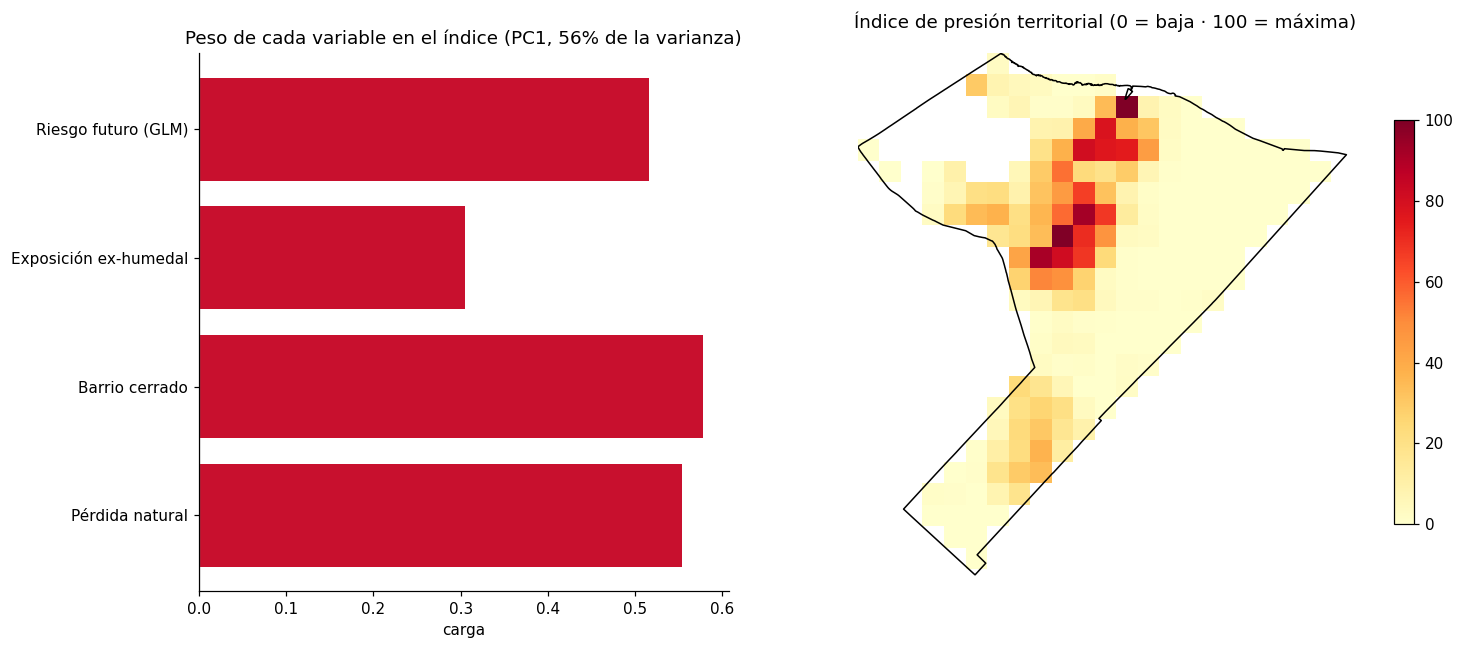

,Índice,Pérdida natural,Barrio cerrado,Exposición ex-humedal,Riesgo futuro (GLM)
14,100.0,67.0,67.6,51.8,6.9
98,100.0,99.9,92.7,3.9,49.7
85,92.4,93.7,87.6,0.5,49.0
109,91.6,99.4,79.6,9.7,36.5
110,81.6,87.0,85.9,0.8,34.6
31,81.0,72.4,75.1,0.1,48.9
21,77.9,98.2,85.9,0.0,25.0
32,76.4,82.1,15.9,39.8,18.2
33,74.8,83.2,41.0,4.7,51.6
99,70.6,100.0,99.7,1.2,0.0


In [58]:
variables = {
    "Pérdida natural": por_bloque(natural0 & urbano_fin)[VALIDO] / n_nat[VALIDO],
    "Barrio cerrado": por_bloque(G[-1] == IDX["Barrio cerrado"])[VALIDO] / n_px[VALIDO],
    "Exposición ex-humedal": por_bloque(ex_humedo & urbano_fin)[VALIDO] / n_px[VALIDO],
}
if "prob" in globals():
    libre_b = np.isfinite(prob)
    n_libre = por_bloque(libre_b)[VALIDO]
    variables["Riesgo futuro (GLM)"] = np.divide(por_bloque(np.where(libre_b, prob, 0))[VALIDO], n_libre,
                                                 out=np.zeros(VALIDO.sum()), where=n_libre > 0)
Xp = pd.DataFrame(variables)
Zp = (Xp - Xp.mean()) / Xp.std(ddof=0).replace(0, 1)
U, Sv, Vt = np.linalg.svd(Zp.to_numpy(), full_matrices=False)
cargas = pd.Series(Vt[0], index=Xp.columns)
signo = np.sign(cargas["Pérdida natural"]) or 1.0
cargas *= signo
pc1 = Zp.to_numpy() @ cargas.to_numpy()
indice = (pc1 - pc1.min()) / (pc1.max() - pc1.min()) * 100
var_expl = Sv ** 2 / np.sum(Sv ** 2)
print(f"La primera componente explica el {var_expl[0]:.0%} de la variación conjunta")

grilla_i = np.full(VALIDO.shape, np.nan); grilla_i[VALIDO] = indice
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [0.8, 1.25]})
a1.barh(cargas.index, cargas.values, color=["#c8102e" if v > 0 else "#2f5fb3" for v in cargas])
a1.axvline(0, color="#999", lw=0.8)
a1.set(title=f"Peso de cada variable en el índice (PC1, {var_expl[0]:.0%} de la varianza)", xlabel="carga")
im = a2.imshow(grilla_i, extent=ext_b, cmap="YlOrRd", vmin=0, vmax=100, interpolation="nearest")
limite.boundary.plot(ax=a2, color="k", linewidth=1)
a2.set_axis_off(); a2.set_title("Índice de presión territorial (0 = baja · 100 = máxima)")
plt.colorbar(im, ax=a2, shrink=0.75)
plt.tight_layout(); plt.savefig(SALIDAS / "fig11_indice_presion.png", dpi=200, bbox_inches="tight"); plt.show()

top = pd.DataFrame({"Índice": indice}).join(Xp.mul(100).round(1)).sort_values("Índice", ascending=False).head(10)
top.round(1)

## 7. Análisis de sensibilidad
Antes de firmar un resultado, un actuario prueba si cambia al mover los supuestos. Aquí se recalcula el indicador central (**% de ex-humedal en el suelo que reemplazan los barrios**) con distintos supuestos:

- **Umbral para fechar un barrio:** 15 %, 25 % o 40 % de su huella urbana.
- **Definición de humedal:** estricta (solo humedal) o amplia (humedal + pastizal, ya que en la ribera muchos pastizales son inundables).

In [59]:
def anio_urbanizacion(codigos, id_barrio, n_barrios, anios, codigos_urbanos=(24,), umbral=0.25):
    ids = id_barrio.ravel(); sel = ids > 0
    total = np.bincount(ids[sel], minlength=n_barrios + 1).astype(float)
    fr = np.vstack([np.bincount(ids[sel], weights=np.isin(codigos[t], codigos_urbanos).ravel()[sel],
                                minlength=n_barrios + 1) / np.maximum(total, 1) for t in range(len(anios))])[:, 1:]
    out = np.full(n_barrios, np.nan)
    for b in range(n_barrios):
        s = np.flatnonzero(fr[:, b] >= umbral)
        if s.size:
            out[b] = anios[s[0]]
    return out


filas = []
for umbral in [0.15, 0.25, 0.40]:
    anio_u = anio_urbanizacion(CODIGOS, ID_BARRIO, len(barrios), ANIOS, CODIGOS_URBANOS, umbral)
    Gs = a_grupos(CODIGOS, ID_BARRIO, anio_u, ANIOS, CODIGO_A_GRUPO, GRUPOS)
    c = suelo_previo_barrios(Gs, ID_BARRIO, anio_u, ANIOS, N)
    for nombre, clases in [("estricta", ["Humedal"]), ("amplia", ["Humedal", "Pastizal"])]:
        if len(c) == 0:
            continue
        num = c[:, [IDX[g] for g in clases]].sum(axis=1, keepdims=True)
        den = c[:, sel].sum(axis=1, keepdims=True)
        p, lo, hi = bootstrap_composicion(np.hstack([num, den - num]), B, rng)
        filas.append({"Umbral fechado": f"{umbral:.0%}", "Definición humedal": nombre, "Barrios usados": len(c),
                      "% ex-humedal": round(p[0] * 100, 1), "IC90": f"{lo[0] * 100:.1f} – {hi[0] * 100:.1f}"})
sensibilidad = pd.DataFrame(filas)
sensibilidad

,Umbral fechado,Definición humedal,Barrios usados,% ex-humedal,IC90
0,15%,estricta,10,16.9,7.7 – 23.8
1,15%,amplia,10,58.7,51.6 – 65.1
2,25%,estricta,12,16.8,7.6 – 23.9
3,25%,amplia,12,59.0,52.5 – 65.1
4,40%,estricta,11,9.6,3.9 – 17.9
5,40%,amplia,11,61.7,53.8 – 73.2


## 8. Mapa interactivo
Muestra cada barrio coloreado según el período en que se urbanizó. Al hacer clic se ve el nombre, la superficie, el año y el suelo que había antes. Se puede abrir `salidas/mapa_interactivo.html` en el navegador.

In [60]:
import folium

cb_por_barrio = {}
for b, a in enumerate(barrios["anio_urb"]):
    if np.isfinite(a) and a != ANIOS[0]:
        t_prev = ANIOS.index(int(a)) - 1
        g = G[t_prev][(ID_BARRIO == b + 1) & (G[t_prev] != NODATA)]
        if g.size:
            cb_por_barrio[b] = np.isin(g, [IDX["Humedal"], IDX["Agua"]]).mean() * 100

bw = barrios.to_crs(4326).copy()
bw["% ex-humedal/agua"] = [round(cb_por_barrio.get(i, np.nan), 1) for i in range(len(bw))]
bw["periodo"] = bw["anio_urb"].apply(lambda a: "sin detectar" if pd.isna(a) else ("≤1989" if a == ANIOS[0] else f"{int(a) - 4}–{int(a)}"))
periodos = sorted(bw["periodo"].unique(), key=lambda s: (s == "sin detectar", s))
paleta = plt.get_cmap("plasma", max(len(periodos), 2))
color_de = {p: "#999999" if p == "sin detectar" else "#%02x%02x%02x" % tuple(int(255 * c) for c in paleta(i)[:3])
            for i, p in enumerate(periodos)}

m = folium.Map(location=[bw.geometry.union_all().centroid.y, bw.geometry.union_all().centroid.x],
               zoom_start=12, tiles="CartoDB positron")
folium.GeoJson(limite.to_crs(4326), name="Límite del partido",
               style_function=lambda f: {"color": "#111", "weight": 2, "fillOpacity": 0}).add_to(m)
for p in periodos:
    sub = bw[bw["periodo"] == p][["nombre", "sup_ha", "anio_urb", "% ex-humedal/agua", "periodo", "geometry"]]
    folium.GeoJson(sub, name=f"Barrios urbanizados {p}",
                   style_function=lambda f, c=color_de[p]: {"color": c, "fillColor": c, "weight": 1, "fillOpacity": 0.7},
                   tooltip=folium.GeoJsonTooltip(["nombre", "sup_ha", "periodo", "% ex-humedal/agua"],
                                                 aliases=["Barrio", "Hectáreas", "Urbanización", "% ex-humedal/agua"],
                                                 localize=True)).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save(SALIDAS / "mapa_interactivo.html")
m

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning:

CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.



## 9. Resultados en números
Los resultados se generan desde los datos para que el texto nunca quede desactualizado respecto del código.

In [61]:
h = rb.loc["Humedal"] * 100
hu = ru.loc["Humedal"] * 100
g_cer = sup.loc["Barrio cerrado"]
q_h = np.percentile(proy[:, -1, IDX["Humedal"]], [5, 50, 95])
print(f"• Barrios cerrados: pasaron de {g_cer.iloc[0]:,.0f} ha en {ANIOS[0]} a {g_cer.iloc[-1]:,.0f} ha en {ANIOS[-1]} "
      f"({g_cer.iloc[-1] / meta['sup_partido_ha']:.1%} del partido).")
print(f"• Del suelo que reemplazaron los barrios cerrados, {h['Estimación']:.1f} % era humedal "
      f"(IC 90 %: {h['IC90 inf']:.1f}–{h['IC90 sup']:.1f}); en el urbano tradicional, {hu['Estimación']:.1f} % "
      f"(IC 90 %: {hu['IC90 inf']:.1f}–{hu['IC90 sup']:.1f}).")
print(f"• Superficie urbanizada sobre ex-humedal o agua en {ANIOS[-1]}: {expo.iloc[-1, :2].sum():,.0f} ha "
      f"({expo.iloc[-1, 2]:.1f} % del humedal/agua de {ANIOS[0]}).")
print(f"• Si las tendencias 2014–2024 se mantienen, el humedal en {anios_proy[-1]} sería de {q_h[1]:,.0f} ha "
      f"(IC 90 %: {q_h[0]:,.0f}–{q_h[2]:,.0f}), frente a {sup.loc['Humedal'].iloc[-1]:,.0f} ha en {ANIOS[-1]}.")
sig = OR[OR["p-valor"] < 0.05]
for var, r in sig.iterrows():
    print(f"• {var}: odds ratio {r['Odds ratio']:.2f} (IC 95 %: {r['IC95 inf']:.2f}–{r['IC95 sup']:.2f}).")

• Barrios cerrados: pasaron de 170 ha en 1989 a 1,441 ha en 2024 (6.6% del partido).
• Del suelo que reemplazaron los barrios cerrados, 16.8 % era humedal (IC 90 %: 8.1–23.6); en el urbano tradicional, 5.8 % (IC 90 %: 3.2–9.2).
• Superficie urbanizada sobre ex-humedal o agua en 2024: 214 ha (8.8 % del humedal/agua de 1989).
• Si las tendencias 2014–2024 se mantienen, el humedal en 2034 sería de 3,657 ha (IC 90 %: 3,378–3,941), frente a 3,754 ha en 2024.
• dist_urbano: odds ratio 0.08 (IC 95 %: 0.02–0.38).
• dist_agua: odds ratio 0.50 (IC 95 %: 0.29–0.86).
• dist_barrio: odds ratio 0.02 (IC 95 %: 0.00–0.11).
• suelo_Humedal: odds ratio 0.13 (IC 95 %: 0.04–0.44).


## 10. Conclusiones

Entre 1989 y 2024, los barrios cerrados de Berazategui pasaron de 170 ha a 1.441 ha (6,6 % del partido). Los resultados principales:

1. **Qué suelo reemplazan los barrios cerrados:** alrededor del 59 % del suelo que ocuparon era humedal o pastizal ribereño (IC 90 %: 52–65 %). El resultado se mantiene con distintos supuestos de fechado (59–62 %, sección 7). Considerando solo humedales en sentido estricto, la proporción es del 17 % (IC 90 %: 8–24 %), una cifra más sensible a esos supuestos. Con 12 barrios analizados, los intervalos son amplios.

2. **Comparación con el urbano tradicional:** del suelo que reemplazaron los barrios cerrados, el 16,8 % era humedal (IC 90 %: 8,1–23,6), frente al 5,8 % en el crecimiento urbano tradicional (IC 90 %: 3,2–9,2). Los intervalos no se superponen: los barrios cerrados consumen proporcionalmente unas tres veces más humedal. El urbano tradicional, en cambio, avanza sobre todo sobre pastizal (67,5 %).

3. **Exposición a inundación:** en 2024 hay 214 ha urbanizadas sobre suelo que en 1989 era humedal o agua (8,8 % de ese total). De esas, 134 ha corresponden a barrios cerrados (63 %), aunque representan una fracción mucho menor de la superficie urbanizada del partido. Casi toda esa exposición se generó entre 1994 y 1999.

4. **Escenario 2034:** si las tendencias de 2014–2024 se mantienen, los barrios cerrados pasarían de 1.441 ha a unas 1.582 ha (IC 90 %: 1.496–1.686). Para el humedal, la proyección (3.657 ha; IC 90 %: 3.378–3.941) no se distingue del valor de 2024 (3.754 ha). Debe leerse con cautela: la superficie de humedal que detecta MapBiomas varía según qué tan húmedo fue cada año.

5. **Dónde está el mayor riesgo de nuevos barrios:** la cercanía a barrios cerrados existentes es el factor más fuerte (odds ratio 0,02 por desvío estándar de distancia; IC 95 %: 0,00–0,11): los barrios nuevos se agrupan junto a los existentes. La cercanía al agua también pesa (odds ratio 0,50; IC 95 %: 0,29–0,86). Con las distancias controladas, un píxel de humedal tiene menos chance de convertirse que uno agropecuario (odds ratio 0,13; IC 95 %: 0,04–0,44). Los barrios llegan a los humedales por su ubicación cerca del río y de otros barrios, no por una preferencia por el humedal en sí. Son asociaciones, no relaciones causales.

**En síntesis:** los barrios cerrados de Berazategui se concentran cerca del río y de otros barrios, y por eso ocupan una proporción de humedal unas tres veces mayor que el crecimiento urbano tradicional. Generan además la mayor parte de la urbanización expuesta sobre ex-humedales. Desde una lógica de gestión de riesgo, las zonas a monitorear son los suelos libres cercanos a los barrios existentes y a la ribera (secciones 6, 6b y 6c).





## 11. Limitaciones
- **Resolución de 30 m:** MapBiomas recomienda usarlo hasta escala 1:100.000. Los barrios chicos (< 5 ha) tienen más error de borde.
- **Año observado ≠ año de lanzamiento:** el año se fecha cuando el barrio se ve urbano, no cuando se aprobó el proyecto. La sección 7 mide cuánto cambia el resultado según el umbral.
- **Ex-humedal o agua como indicador de riesgo:** no reemplaza un mapa de peligro hídrico oficial. Es un indicador de exposición, no de probabilidad de inundación.
- **Variabilidad del humedal:** la superficie de humedal que detecta MapBiomas cambia según qué tan húmedo fue cada año, lo que agrega ruido a las tendencias.
- **Markov homogéneo:** supone que las tasas de 2014–2024 se mantienen. No incluye cambios de normativa ni de mercado.
- **GLM:** muestra asociaciones, no causalidad. La correlación espacial se trata con errores agrupados por bloque, pero puede quedar dependencia residual.
- **Límite del partido:** se usó el polígono de OpenStreetMap (21.818 ha), que probablemente incluye una franja del Río de la Plata; el límite oficial del IGN daría una superficie menor.
- **Barrios de OpenStreetMap:** 9 de los 20 barrios no tienen nombre en OSM y se identificaron por sus etiquetas. Conviene validarlos con el Registro Provincial de Urbanizaciones Cerradas.
- **Arbustales sin clasificar:** los códigos 66 y 77 de MapBiomas (arbustales cerrados y abiertos) quedaron agrupados en "Otro". Representan menos del 0,4 % del partido, por lo que no alteran los resultados; en una versión futura se agruparían con "Bosque".


## Fuentes y bibliografía
**Datos**
- MapBiomas Argentina. *Colección 2 de mapas anuales de cobertura y uso del suelo (1985–2024)*. argentina.mapbiomas.org
- MapBiomas Argentina. *Códigos de la leyenda – Colección 2* (Leyenda_Code.pdf).
- Instituto Geográfico Nacional. Cartografía y límites administrativos. ign.gob.ar
- Provincia de Buenos Aires. Registro Provincial de Urbanizaciones Cerradas – URBASIG.
- OpenStreetMap contributors. openstreetmap.org/copyright
- Wetlands International (2019). *Urbanizaciones cerradas en humedales*.

**Herramientas**: pandas, GeoPandas, rasterio, Matplotlib, Plotly, statsmodels, SciPy, Folium, OSMnx, Earth Engine API, Project Jupyter.

## Descargar resultados (Colab)
Sin Drive, los archivos se borran al cerrar Colab. Esta celda junta `salidas/` (figuras, tablas, mapa interactivo) en un .zip y lo descarga al iPad (app Archivos).

In [62]:
import shutil, sys
shutil.make_archive("salidas_tp", "zip", "salidas")
if "google.colab" in sys.modules:
    from google.colab import files
    files.download("salidas_tp.zip")
print("Listo: salidas_tp.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Listo: salidas_tp.zip
